# 09 — Four-model representation comparison

This notebook compares four self-supervised learning methods trained with a
ResNet-18 backbone:

- SimCLR
- DeepCluster
- SimSiam
- SwAV

The comparison uses the frozen
`pooled_broad_p80_10_10_v1` validation benchmark.

## Evaluation policy

- All four models are evaluated on the same validation crystals.
- The held-out test split is not loaded.
- Training objectives are not compared directly because each method optimises
  a different loss.
- Shared downstream metrics are used instead.
- A common clustering calculation is performed for visual comparison.
- Representative cluster images come only from the validation split.
- Clusters are exploratory groups, not automatically geological populations.


In [1]:
from __future__ import annotations

import json
import math
import sys
from itertools import combinations
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as NotebookImage
from IPython.display import display
from PIL import Image, ImageDraw, ImageFont, ImageOps
from sklearn.metrics import adjusted_rand_score

IRP_ROOT = Path(
    "/home/ars223/MSc-GEMS/IRP26"
)

DEV_ROOT = (
    IRP_ROOT
    / "plagnetplus-dev"
)

sys.path.insert(
    0,
    str(DEV_ROOT / "src"),
)

from plagnetplus.evaluation import (
    evaluate_kmeans_run,
    fit_deterministic_pca,
    l2_normalise_rows,
    load_embedding_bundle,
    load_embedding_manifest,
    validate_embedding_manifest_alignment,
)

BENCHMARK_ROOT = (
    IRP_ROOT
    / "data"
    / "processed"
    / "plagnetplus"
    / "ssl_unified_v1"
    / "benchmarks"
    / "pooled_broad_p80_10_10_v1"
)

UNIFIED_ROOT = (
    IRP_ROOT
    / "data"
    / "processed"
    / "plagnetplus"
    / "ssl_unified_v1"
)

VALIDATION_MANIFEST_PATH = (
    BENCHMARK_ROOT
    / "manifests"
    / "crystals_validation.csv"
)

OUTPUT_ROOT = (
    IRP_ROOT
    / "runs"
    / "analysis"
    / "comparison"
    / "four_model_validation_v1"
)

FIGURE_ROOT = OUTPUT_ROOT / "figures"
TABLE_ROOT = OUTPUT_ROOT / "tables"
CLUSTER_ROOT = OUTPUT_ROOT / "clustering"
IMAGE_CLUSTER_ROOT = (
    OUTPUT_ROOT
    / "cluster_images"
)
METADATA_ROOT = OUTPUT_ROOT / "metadata"

for directory in (
    OUTPUT_ROOT,
    FIGURE_ROOT,
    TABLE_ROOT,
    CLUSTER_ROOT,
    IMAGE_CLUSTER_ROOT,
    METADATA_ROOT,
):
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

MODEL_SPECS = {
    "SimCLR": {
        "method": "simclr",
        "run_name": (
            "simclr_resnet18_pooled_broad_"
            "natural_seed42_full_3408095"
        ),
    },
    "DeepCluster": {
        "method": "deepcluster",
        "run_name": (
            "deepcluster_resnet18_pooled_broad_"
            "natural_seed42_full_3425705"
        ),
    },
    "SimSiam": {
        "method": "simsiam",
        "run_name": (
            "simsiam_resnet18_pooled_broad_"
            "natural_seed42_full_3438756"
        ),
    },
    "SwAV": {
        "method": "swav",
        "run_name": (
            "swav_resnet18_pooled_broad_"
            "natural_seed42_full_3447013"
        ),
    },
}

for display_name, spec in MODEL_SPECS.items():
    method = spec["method"]
    run_name = spec["run_name"]

    spec["run_root"] = (
        IRP_ROOT
        / "runs"
        / "hpc"
        / method
        / run_name
    )

    spec["analysis_root"] = (
        IRP_ROOT
        / "runs"
        / "analysis"
        / method
        / f"{run_name}_v1"
    )

    spec["embedding_path"] = (
        spec["run_root"]
        / "embeddings"
        / "validation_backbone_embeddings.npz"
    )

pd.set_option(
    "display.max_columns",
    100,
)

pd.set_option(
    "display.width",
    180,
)

def json_ready(value: Any) -> Any:
    if isinstance(value, dict):
        return {
            str(key): json_ready(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            json_ready(item)
            for item in value
        ]

    if isinstance(value, np.ndarray):
        return value.tolist()

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, Path):
        return str(value)

    if (
        isinstance(value, float)
        and not math.isfinite(value)
    ):
        return None

    return value

def write_json(
    path: Path,
    value: dict[str, Any],
) -> None:
    path.write_text(
        json.dumps(
            json_ready(value),
            indent=2,
            sort_keys=True,
        )
        + "\n",
        encoding="utf-8",
    )

def read_json(
    path: Path,
) -> dict[str, Any]:
    return json.loads(
        path.read_text(
            encoding="utf-8"
        )
    )

def align_manifest(
    bundle,
    manifest: pd.DataFrame,
) -> pd.DataFrame:
    keys = pd.DataFrame(
        {
            "crystal_id": (
                bundle.crystal_ids.astype(str)
            ),
            "manifest_order": (
                bundle.manifest_orders.astype(
                    np.int64
                )
            ),
        }
    )

    aligned = keys.merge(
        manifest,
        on=[
            "crystal_id",
            "manifest_order",
        ],
        how="left",
        validate="one_to_one",
        sort=False,
        indicator=True,
    )

    if not bool(
        (aligned["_merge"] == "both").all()
    ):
        raise RuntimeError(
            "Embedding and manifest rows "
            "could not be aligned."
        )

    return aligned.drop(
        columns="_merge"
    )

def first_column(
    frame: pd.DataFrame,
    candidates: tuple[str, ...],
) -> str | None:
    lookup = {
        str(column).lower(): str(column)
        for column in frame.columns
    }

    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]

    return None

print("Output root:", OUTPUT_ROOT)
print("Validation manifest:", VALIDATION_MANIFEST_PATH)
print("Python:", sys.executable)


Output root: /home/ars223/MSc-GEMS/IRP26/runs/analysis/comparison/four_model_validation_v1
Validation manifest: /home/ars223/MSc-GEMS/IRP26/data/processed/plagnetplus/ssl_unified_v1/benchmarks/pooled_broad_p80_10_10_v1/manifests/crystals_validation.csv
Python: /home/ars223/MSc-GEMS/IRP26/plagnetplus-dev/.venv/bin/python


## 1. Experimental comparability

Before comparing scores, the notebook verifies that each embedding contains the
same number of validation crystals and uses the same 512-dimensional backbone
representation.

This matters because performance numbers are only meaningful when the models
are evaluated on the same observations.


In [2]:
validation_manifest_raw = (
    load_embedding_manifest(
        VALIDATION_MANIFEST_PATH
    )
)

bundle_metadata = []
model_bundles = {}
aligned_manifests = {}

reference_ids = None
reference_orders = None

for display_name, spec in MODEL_SPECS.items():
    embedding_path = spec["embedding_path"]

    if not embedding_path.is_file():
        raise FileNotFoundError(
            embedding_path
        )

    bundle = load_embedding_bundle(
        embedding_path,
        expected_feature_dimension=512,
    )

    alignment = (
        validate_embedding_manifest_alignment(
            bundle,
            validation_manifest_raw,
        )
    )

    aligned = align_manifest(
        bundle,
        validation_manifest_raw,
    )

    if bundle.features.shape != (
        14919,
        512,
    ):
        raise RuntimeError(
            f"Unexpected shape for "
            f"{display_name}: "
            f"{bundle.features.shape}"
        )

    if not np.isfinite(
        bundle.features
    ).all():
        raise RuntimeError(
            f"{display_name} contains "
            "non-finite embeddings."
        )

    if reference_ids is None:
        reference_ids = (
            bundle.crystal_ids.astype(str)
        )

        reference_orders = (
            bundle.manifest_orders.astype(
                np.int64
            )
        )

    else:
        if not np.array_equal(
            reference_ids,
            bundle.crystal_ids.astype(str),
        ):
            raise RuntimeError(
                f"{display_name} crystal IDs "
                "do not match the shared order."
            )

        if not np.array_equal(
            reference_orders,
            bundle.manifest_orders.astype(
                np.int64
            ),
        ):
            raise RuntimeError(
                f"{display_name} manifest orders "
                "do not match."
            )

    model_bundles[display_name] = bundle
    aligned_manifests[display_name] = aligned

    bundle_metadata.append(
        {
            "Model": display_name,
            "Backbone": "ResNet-18",
            "Validation crystals": (
                bundle.features.shape[0]
            ),
            "Feature dimensions": (
                bundle.features.shape[1]
            ),
            "Finite embeddings": True,
            "Manifest alignment": "PASS",
            "Test split accessed": False,
        }
    )

comparability_table = pd.DataFrame(
    bundle_metadata
)

comparability_table.to_csv(
    TABLE_ROOT
    / "experimental_comparability.csv",
    index=False,
)

display(comparability_table)

print(
    "EXPERIMENTAL COMPARABILITY: PASS"
)
print("TEST SPLIT ACCESSED: NO")


,Model,Backbone,Validation crystals,Feature dimensions,Finite embeddings,Manifest alignment,Test split accessed
0,SimCLR,ResNet-18,14919,512,True,PASS,False
1,DeepCluster,ResNet-18,14919,512,True,PASS,False
2,SimSiam,ResNet-18,14919,512,True,PASS,False
3,SwAV,ResNet-18,14919,512,True,PASS,False


EXPERIMENTAL COMPARABILITY: PASS
TEST SPLIT ACCESSED: NO


## 2. Shared model metrics

The table below focuses on downstream representation quality rather than the
four different training losses.

### Metric guide

- **Median silhouette:** measures how much closer crystals are to their own
  cluster than to neighbouring clusters. Higher values indicate clearer
  separation.
- **Stability ARI:** measures whether repeated clustering runs produce similar
  assignments. Higher values indicate more reproducible structure.
- **FCT cross-sample P@10:** measures how often the ten nearest crystals to an
  FCT query are also FCT crystals after same-sample neighbours are excluded.
- **Locality macro-F1:** measures how well a simple classifier can recover
  locality from frozen embeddings while giving each locality equal importance.
- **Source-image enrichment:** measures whether neighbours come from the same
  source image more often than expected by chance. Lower values are generally
  preferable because strong enrichment may indicate acquisition leakage.
- **Effective rank:** estimates how many independent directions contain useful
  variation. Very low values can indicate a compressed or partly collapsed
  representation.
- **GPU hours:** measures training cost. Lower values are preferable when model
  quality is otherwise similar.

A missing value means the diagnostic was not available. It does not mean the
model scored zero.


,Model,Median silhouette,Stability ARI,FCT cross-sample P@10,Locality macro-F1,Source-image enrichment@10,Effective rank,GPU hours,Metric source
0,SimCLR,0.0695,0.6111,0.0912,0.4731,2.1985,33.6802,8.0493,/home/ars223/MSc-GEMS/IRP26/runs/analysis/simclr/simclr_resnet18_pooled_broad_natural_seed42_full_3408095_v1/analysis_summary.json
1,DeepCluster,0.1686,0.6934,0.1096,Not available,4.1829,29.3487,3.2769,/home/ars223/MSc-GEMS/IRP26/runs/analysis/deepcluster/deepcluster_resnet18_pooled_broad_natural_seed42_full_3425705_v1/analysis_summary.json
2,SimSiam,0.1479,0.4750,0.0884,0.6018,Not available,7.8902,5.8022,/home/ars223/MSc-GEMS/IRP26/runs/analysis/simsiam/simsiam_resnet18_pooled_broad_natural_seed42_full_3438756_v1/analysis_summary.json
3,SwAV,0.2939,0.6230,0.2362,0.4268,Not available,48.7477,5.8433,/home/ars223/MSc-GEMS/IRP26/runs/analysis/swav/swav_resnet18_pooled_broad_natural_seed42_full_3447013_v1/analysis_summary.json


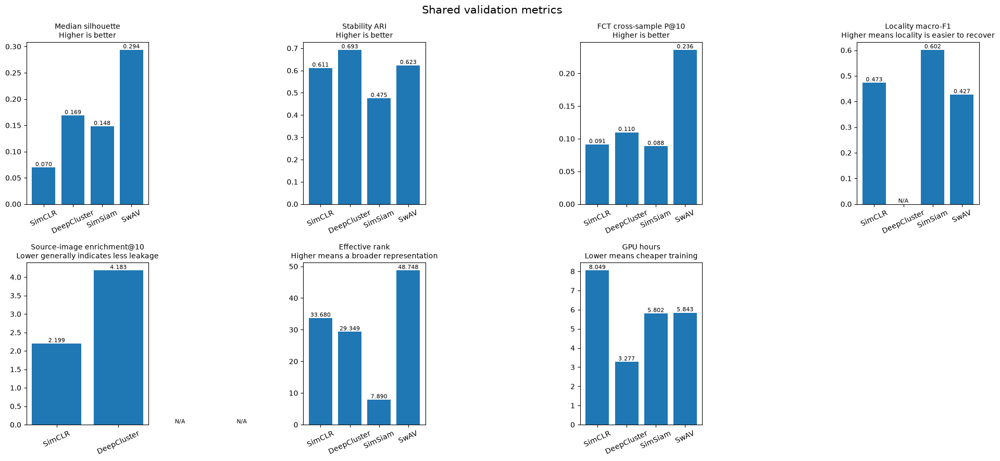

In [3]:
FALLBACK_METRICS = {
    "SimCLR": {
        "median_silhouette_across_k": 0.0695,
        "median_stability_ari_across_k": 0.6111,
        "automatic_fct_cross_sample_p10_raw": 0.0912,
        "expert_cross_sample_texture_p10": None,
        "locality_macro_f1": 0.4731,
        "source_image_enrichment_at10_raw": 2.1985,
        "validation_effective_rank": 33.6802,
        "gpu_hours": 8.0493,
    },
    "DeepCluster": {
        "median_silhouette_across_k": 0.16859,
        "median_stability_ari_across_k": 0.69337,
        "automatic_fct_cross_sample_p10_raw": 0.10964,
        "expert_cross_sample_texture_p10": None,
        "locality_macro_f1": None,
        "source_image_enrichment_at10_raw": 4.18291,
        "validation_effective_rank": 29.34867,
        "gpu_hours": 3.27694,
    },
    "SimSiam": {
        "median_silhouette_across_k": 0.1479167640209198,
        "median_stability_ari_across_k": 0.4750204081494453,
        "automatic_fct_cross_sample_p10_raw": 0.08837510803802939,
        "expert_cross_sample_texture_p10": None,
        "locality_macro_f1": 0.6017712699351833,
        "source_image_enrichment_at10_raw": None,
        "validation_effective_rank": 7.8902177826188105,
        "gpu_hours": 5.802153604833357,
    },
    "SwAV": {
        "median_silhouette_across_k": 0.2938680648803711,
        "median_stability_ari_across_k": 0.6229684686291584,
        "automatic_fct_cross_sample_p10_raw": 0.23617113223854796,
        "expert_cross_sample_texture_p10": None,
        "locality_macro_f1": 0.4267707745069623,
        "source_image_enrichment_at10_raw": None,
        "validation_effective_rank": 48.747708535595066,
        "gpu_hours": 5.8432944832321825,
    },
}

def extract_summary_metrics(
    display_name: str,
    analysis_root: Path,
) -> tuple[dict[str, Any], str]:
    result = dict(
        FALLBACK_METRICS[display_name]
    )

    summary_candidates = [
        analysis_root
        / "analysis_summary.json",
    ]

    summary_candidates.extend(
        sorted(
            analysis_root.rglob(
                "analysis_summary.json"
            )
        )
    )

    for path in summary_candidates:
        if not path.is_file():
            continue

        payload = read_json(path)

        comparison = payload.get(
            "comparison_metrics"
        )

        if isinstance(comparison, dict):
            for key in result:
                if key in comparison:
                    result[key] = comparison[key]

            return result, str(path)

    csv_candidates = sorted(
        analysis_root.rglob(
            "*summary*.csv"
        )
    )

    for path in csv_candidates:
        try:
            frame = pd.read_csv(path)
        except Exception:
            continue

        if len(frame) < 1:
            continue

        row = frame.iloc[0].to_dict()
        found = False

        for key in result:
            if key in row:
                value = row[key]

                if pd.isna(value):
                    value = None

                result[key] = value
                found = True

        if found:
            return result, str(path)

    return result, "recorded comparison values"

metric_rows = []

for display_name, spec in MODEL_SPECS.items():
    metrics, source = extract_summary_metrics(
        display_name,
        spec["analysis_root"],
    )

    metric_rows.append(
        {
            "Model": display_name,
            "Median silhouette": (
                metrics[
                    "median_silhouette_across_k"
                ]
            ),
            "Stability ARI": (
                metrics[
                    "median_stability_ari_across_k"
                ]
            ),
            "FCT cross-sample P@10": (
                metrics[
                    "automatic_fct_cross_sample_p10_raw"
                ]
            ),
            "Locality macro-F1": (
                metrics["locality_macro_f1"]
            ),
            "Source-image enrichment@10": (
                metrics[
                    "source_image_enrichment_at10_raw"
                ]
            ),
            "Effective rank": (
                metrics[
                    "validation_effective_rank"
                ]
            ),
            "GPU hours": (
                metrics["gpu_hours"]
            ),
            "Metric source": source,
        }
    )

metrics_table = pd.DataFrame(
    metric_rows
)

metrics_table.to_csv(
    TABLE_ROOT
    / "four_model_metrics.csv",
    index=False,
)

numeric_columns = [
    "Median silhouette",
    "Stability ARI",
    "FCT cross-sample P@10",
    "Locality macro-F1",
    "Source-image enrichment@10",
    "Effective rank",
    "GPU hours",
]

display(
    metrics_table.style.format(
        {
            column: "{:.4f}"
            for column in numeric_columns
        },
        na_rep="Not available",
    )
)

plot_specs = [
    (
        "Median silhouette",
        "Higher is better",
    ),
    (
        "Stability ARI",
        "Higher is better",
    ),
    (
        "FCT cross-sample P@10",
        "Higher is better",
    ),
    (
        "Locality macro-F1",
        "Higher means locality is easier to recover",
    ),
    (
        "Source-image enrichment@10",
        "Lower generally indicates less leakage",
    ),
    (
        "Effective rank",
        "Higher means a broader representation",
    ),
    (
        "GPU hours",
        "Lower means cheaper training",
    ),
]

figure, axes = plt.subplots(
    2,
    4,
    figsize=(19, 9),
)

axes = axes.ravel()

for axis, (metric, subtitle) in zip(
    axes,
    plot_specs,
):
    values = metrics_table[
        metric
    ].astype(float)

    axis.bar(
        metrics_table["Model"],
        values,
    )

    axis.set_title(
        f"{metric}\n{subtitle}",
        fontsize=10,
    )

    axis.tick_params(
        axis="x",
        rotation=25,
    )

    for index, value in enumerate(values):
        if np.isfinite(value):
            axis.text(
                index,
                value,
                f"{value:.3f}",
                ha="center",
                va="bottom",
                fontsize=8,
            )
        else:
            axis.text(
                index,
                0,
                "N/A",
                ha="center",
                va="bottom",
                fontsize=8,
            )

axes[-1].axis("off")

figure.suptitle(
    "Shared validation metrics",
    fontsize=15,
)

figure.tight_layout()

metrics_figure = (
    FIGURE_ROOT
    / "shared_metrics_dashboard.png"
)

figure.savefig(
    metrics_figure,
    dpi=180,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)


### Reading the metric comparison

No single metric is enough to select a model.

For example, a model can produce well-separated clusters but still group
crystals mainly by imaging conditions. The metrics should therefore be read
together:

1. Check that the representation has not collapsed.
2. Examine cluster separation and stability.
3. Examine cross-sample retrieval.
4. Check locality and acquisition leakage.
5. Compare the result with training cost.


## 3. Reported clustering behaviour across cluster counts

Where available, the next section reads the clustering tables produced by each
model-specific analysis.

The number of clusters is written as \(k\). A larger \(k\) creates more,
smaller groups. A useful representation should not only work at one carefully
chosen value of \(k\); its behaviour should remain reasonably consistent over
several values.


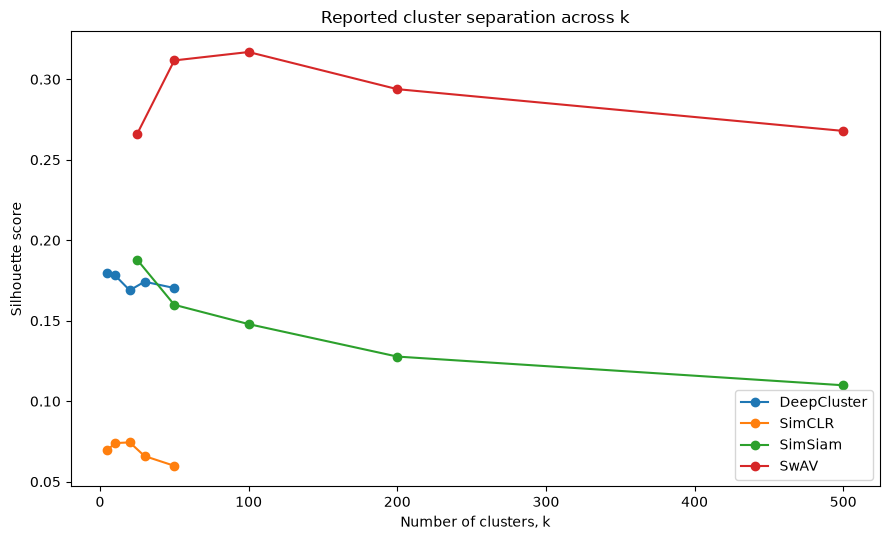

,number_of_clusters,seed,silhouette,davies_bouldin,calinski_harabasz,Model,Source
50,5,11,0.179350,NaN,NaN,DeepCluster,/home/ars223/MSc-GEMS/IRP26/runs/analysis/deep...
51,5,22,0.165208,NaN,NaN,DeepCluster,/home/ars223/MSc-GEMS/IRP26/runs/analysis/deep...
52,5,33,0.165184,NaN,NaN,DeepCluster,/home/ars223/MSc-GEMS/IRP26/runs/analysis/deep...
53,5,44,0.179350,NaN,NaN,DeepCluster,/home/ars223/MSc-GEMS/IRP26/runs/analysis/deep...
54,5,55,0.179435,NaN,NaN,DeepCluster,/home/ars223/MSc-GEMS/IRP26/runs/analysis/deep...
...,...,...,...,...,...,...,...
125,200,43,0.291677,1.059130,936.489577,SwAV,/home/ars223/MSc-GEMS/IRP26/runs/analysis/swav...
126,200,44,0.301515,1.041793,945.056469,SwAV,/home/ars223/MSc-GEMS/IRP26/runs/analysis/swav...
127,500,42,0.267924,1.045233,759.284216,SwAV,/home/ars223/MSc-GEMS/IRP26/runs/analysis/swav...
128,500,43,0.276462,1.034890,765.578155,SwAV,/home/ars223/MSc-GEMS/IRP26/runs/analysis/swav...


In [4]:
def normalise_clustering_table(
    frame: pd.DataFrame,
) -> pd.DataFrame | None:
    aliases = {
        "number_of_clusters": (
            "number_of_clusters",
            "n_clusters",
            "clusters",
            "k",
        ),
        "seed": (
            "seed",
            "random_seed",
        ),
        "silhouette": (
            "silhouette",
            "silhouette_score",
        ),
        "davies_bouldin": (
            "davies_bouldin",
            "davies_bouldin_score",
        ),
        "calinski_harabasz": (
            "calinski_harabasz",
            "calinski_harabasz_score",
        ),
    }

    lookup = {
        str(column).lower(): column
        for column in frame.columns
    }

    selected = {}

    for standard_name, candidates in aliases.items():
        for candidate in candidates:
            if candidate.lower() in lookup:
                selected[standard_name] = (
                    lookup[candidate.lower()]
                )
                break

    if (
        "number_of_clusters" not in selected
        or "silhouette" not in selected
    ):
        return None

    output = pd.DataFrame()

    for standard_name, source_name in selected.items():
        output[standard_name] = (
            frame[source_name]
        )

    if "seed" not in output:
        output["seed"] = 42

    return output

reported_clustering_frames = []

for display_name, spec in MODEL_SPECS.items():
    candidates = sorted(
        spec["analysis_root"].rglob(
            "*.csv"
        )
    )

    model_table = None

    for path in candidates:
        try:
            frame = pd.read_csv(path)
        except Exception:
            continue

        normalised = normalise_clustering_table(
            frame
        )

        if normalised is None:
            continue

        model_table = normalised.copy()
        model_table["Model"] = display_name
        model_table["Source"] = str(path)
        break

    if model_table is not None:
        reported_clustering_frames.append(
            model_table
        )

if reported_clustering_frames:
    reported_clustering = pd.concat(
        reported_clustering_frames,
        ignore_index=True,
    )

    reported_clustering.to_csv(
        TABLE_ROOT
        / "reported_clustering_across_k.csv",
        index=False,
    )

    figure, axis = plt.subplots(
        figsize=(9, 5.5)
    )

    for display_name, group in (
        reported_clustering.groupby("Model")
    ):
        seed42 = group.loc[
            group["seed"].astype(int) == 42
        ].copy()

        if seed42.empty:
            seed42 = group.copy()

        seed42 = (
            seed42.sort_values(
                "number_of_clusters"
            )
            .drop_duplicates(
                "number_of_clusters"
            )
        )

        axis.plot(
            seed42["number_of_clusters"],
            seed42["silhouette"],
            marker="o",
            label=display_name,
        )

    axis.set_xlabel(
        "Number of clusters, k"
    )
    axis.set_ylabel(
        "Silhouette score"
    )
    axis.set_title(
        "Reported cluster separation across k"
    )
    axis.legend()

    figure.tight_layout()

    figure.savefig(
        FIGURE_ROOT
        / "reported_silhouette_across_k.png",
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(figure)

    display(
        reported_clustering.sort_values(
            [
                "Model",
                "number_of_clusters",
                "seed",
            ]
        )
    )

else:
    reported_clustering = pd.DataFrame()

    print(
        "No compatible reported clustering "
        "tables were found."
    )


## 4. Common clustering comparison

The reported metrics above may have been generated by slightly different
notebook implementations. To create one directly comparable visual analysis,
this section reclusters every model using exactly the same procedure:

1. L2-normalise each 512-dimensional embedding.
2. Reduce it to 50 principal components.
3. Run k-means with \(k=50\) and seed 42.
4. Evaluate all models using the same deterministic silhouette sample.

This calculation is for validation comparison and visualisation. It does not
replace the full multi-\(k\), multi-seed results.


Processing common clustering: SimCLR


Processing common clustering: DeepCluster


Processing common clustering: SimSiam


Processing common clustering: SwAV


,Model,k,Silhouette,Davies-Bouldin,Calinski-Harabasz,Occupied clusters,Normalised size entropy,Smallest cluster,Largest cluster,Largest cluster fraction
0,SimCLR,50,0.0541,2.5328,224.5,50,0.9924,155,475,0.0318
1,DeepCluster,50,0.1671,1.6182,700.2,50,0.9774,129,699,0.0469
2,SimSiam,50,0.1599,1.4062,1743.6,50,0.9771,140,700,0.0469
3,SwAV,50,0.3117,1.1754,1126.5,50,0.9719,100,729,0.0489


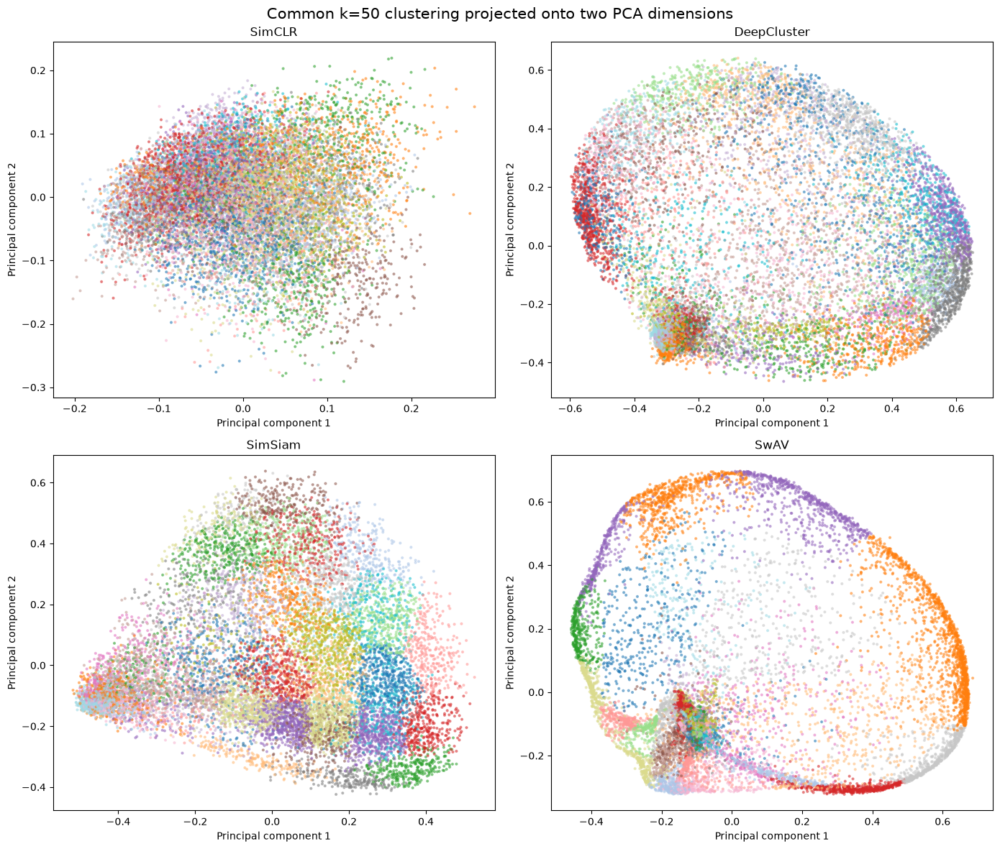

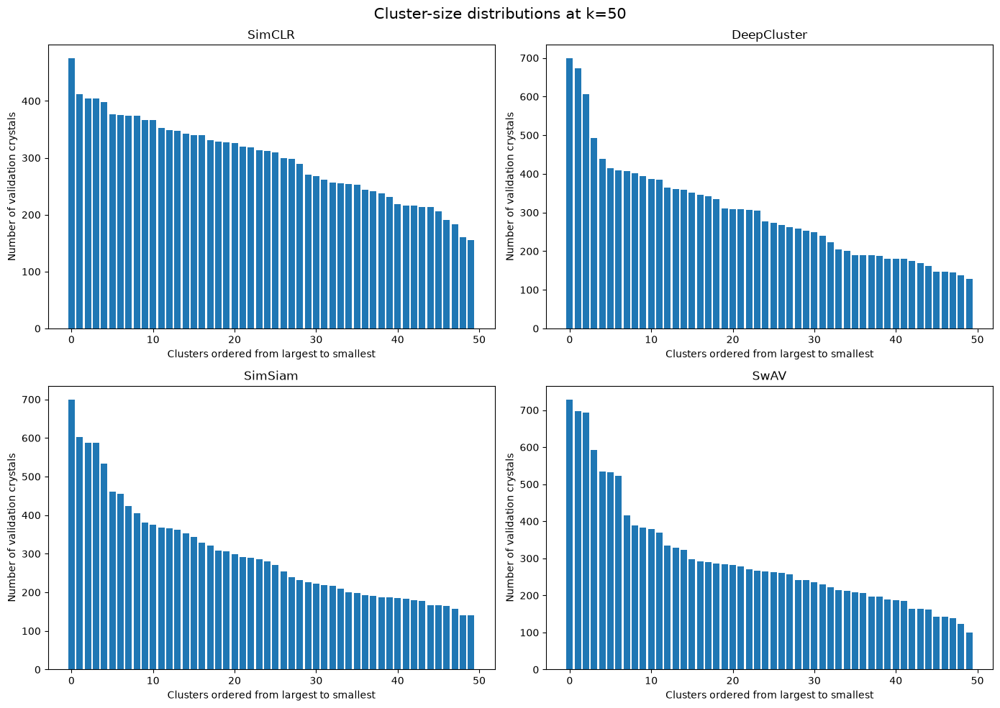

In [5]:
COMMON_K = 50
COMMON_SEED = 42

rng = np.random.default_rng(
    COMMON_SEED
)

silhouette_indices = np.sort(
    rng.choice(
        14919,
        size=5000,
        replace=False,
    )
)

common_results = {}
common_metric_rows = []

for display_name, bundle in (
    model_bundles.items()
):
    print(
        f"Processing common clustering: "
        f"{display_name}"
    )

    normalised_features = (
        l2_normalise_rows(
            bundle.features
        )
    )

    pca_result = fit_deterministic_pca(
        normalised_features,
        retained_components=50,
    )

    labels, centroids, metrics = (
        evaluate_kmeans_run(
            pca_result.coordinates,
            number_of_clusters=COMMON_K,
            seed=COMMON_SEED,
            silhouette_indices=(
                silhouette_indices
            ),
        )
    )

    counts = np.bincount(
        labels,
        minlength=COMMON_K,
    )

    proportions = (
        counts
        / counts.sum()
    )

    occupied = proportions[
        proportions > 0
    ]

    cluster_entropy = float(
        -np.sum(
            occupied
            * np.log(occupied)
        )
        / np.log(COMMON_K)
    )

    common_results[display_name] = {
        "coordinates": (
            pca_result.coordinates
        ),
        "labels": labels,
        "centroids": centroids,
        "counts": counts,
        "metrics": metrics,
        "crystal_ids": (
            bundle.crystal_ids.astype(str)
        ),
        "manifest_orders": (
            bundle.manifest_orders.astype(
                np.int64
            )
        ),
    }

    common_metric_rows.append(
        {
            "Model": display_name,
            "k": COMMON_K,
            "Silhouette": (
                metrics["silhouette"]
            ),
            "Davies-Bouldin": (
                metrics.get(
                    "davies_bouldin"
                )
            ),
            "Calinski-Harabasz": (
                metrics.get(
                    "calinski_harabasz"
                )
            ),
            "Occupied clusters": int(
                np.count_nonzero(counts)
            ),
            "Normalised size entropy": (
                cluster_entropy
            ),
            "Smallest cluster": int(
                counts.min()
            ),
            "Largest cluster": int(
                counts.max()
            ),
            "Largest cluster fraction": float(
                counts.max()
                / counts.sum()
            ),
        }
    )

    assignment_table = pd.DataFrame(
        {
            "crystal_id": (
                bundle.crystal_ids
            ),
            "manifest_order": (
                bundle.manifest_orders
            ),
            "cluster": labels,
        }
    )

    assignment_table.to_csv(
        CLUSTER_ROOT
        / (
            f"{MODEL_SPECS[display_name]['method']}"
            f"_common_k50_assignments.csv"
        ),
        index=False,
    )

common_metrics = pd.DataFrame(
    common_metric_rows
)

common_metrics.to_csv(
    TABLE_ROOT
    / "common_k50_clustering_metrics.csv",
    index=False,
)

display(
    common_metrics.style.format(
        {
            "Silhouette": "{:.4f}",
            "Davies-Bouldin": "{:.4f}",
            "Calinski-Harabasz": "{:.1f}",
            "Normalised size entropy": "{:.4f}",
            "Largest cluster fraction": "{:.4f}",
        },
        na_rep="Not available",
    )
)

figure, axes = plt.subplots(
    2,
    2,
    figsize=(14, 12),
)

for axis, display_name in zip(
    axes.ravel(),
    MODEL_SPECS,
):
    result = common_results[
        display_name
    ]

    scatter = axis.scatter(
        result["coordinates"][:, 0],
        result["coordinates"][:, 1],
        c=result["labels"],
        s=4,
        alpha=0.45,
        cmap="tab20",
    )

    axis.set_title(display_name)
    axis.set_xlabel("Principal component 1")
    axis.set_ylabel("Principal component 2")

figure.suptitle(
    "Common k=50 clustering projected onto two PCA dimensions",
    fontsize=15,
)

figure.tight_layout()

cluster_scatter_path = (
    FIGURE_ROOT
    / "common_k50_pca_clusters.png"
)

figure.savefig(
    cluster_scatter_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)

figure, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10),
)

for axis, display_name in zip(
    axes.ravel(),
    MODEL_SPECS,
):
    counts = np.sort(
        common_results[
            display_name
        ]["counts"]
    )[::-1]

    axis.bar(
        np.arange(COMMON_K),
        counts,
    )

    axis.set_title(display_name)
    axis.set_xlabel(
        "Clusters ordered from largest to smallest"
    )
    axis.set_ylabel(
        "Number of validation crystals"
    )

figure.suptitle(
    "Cluster-size distributions at k=50",
    fontsize=15,
)

figure.tight_layout()

figure.savefig(
    FIGURE_ROOT
    / "common_k50_cluster_sizes.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)


### Understanding the clustering plots

Each point represents one validation crystal. Its colour is the k-means cluster
assigned by that model.

The horizontal and vertical axes are the first two principal components. They
show the largest directions of variation, but they contain only part of the
full 50-dimensional clustering space. Overlap in this two-dimensional picture
therefore does not necessarily mean the high-dimensional clusters are
identical.

The cluster-size charts help identify imbalance. A few extremely large
clusters and many tiny clusters can indicate that \(k=50\) is too large or
that the representation contains uneven structure.


## 5. Elbow-method estimate of the number of clusters

The elbow method examines how much variation remains inside the clusters as the
number of clusters, \(k\), increases.

This remaining variation is called **inertia** or the
**within-cluster sum of squares**. Lower inertia means that crystals lie closer
to their assigned cluster centres.

Inertia always decreases when more clusters are added. The aim is therefore
not simply to find the lowest value. Instead, the elbow is the point where
adding more clusters begins to produce much smaller improvements.

To keep the calculation practical and directly comparable:

- the same deterministic sample of 5,000 validation crystals is used for every
  model;
- clustering uses each model's existing 50-component PCA representation;
- the same candidate values of \(k\), random seed and k-means settings are used;
- the held-out test split remains untouched.

The automatically estimated elbow is a useful candidate rather than a final
answer. It should be considered together with cluster stability, silhouette
scores, cluster-size balance and inspection of the representative crystal
images.


Elbow analysis: SimCLR
  k=  2 inertia=335.179


  k=  3 inertia=320.886
  k=  4 inertia=307.783
  k=  5 inertia=297.929


  k=  6 inertia=289.149
  k=  8 inertia=275.523


  k= 10 inertia=264.528
  k= 12 inertia=256.374


  k= 15 inertia=246.045


...

  k= 50 inertia=644.796


  k= 60 inertia=545.687


  k= 75 inertia=449.438


  k=100 inertia=357.751


,Model,Estimated elbow k,Minimum tested k,Maximum tested k,Sample crystals,PCA components
0,SimCLR,25,2,100,5000,50
1,DeepCluster,25,2,100,5000,50
2,SimSiam,15,2,100,5000,50
3,SwAV,25,2,100,5000,50


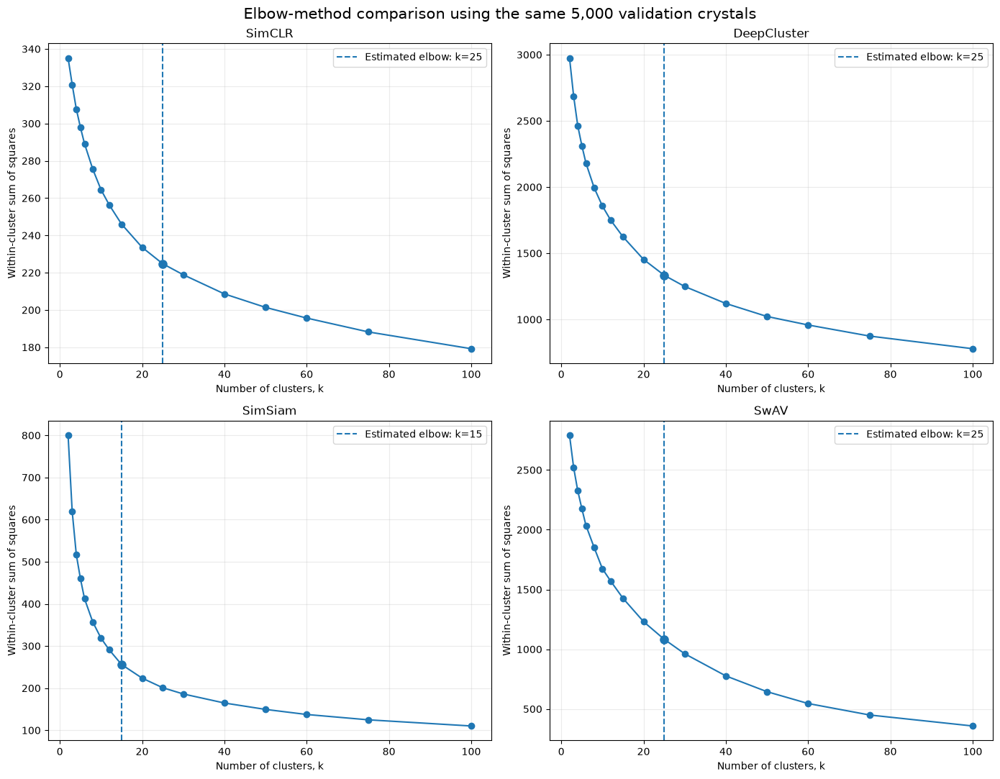

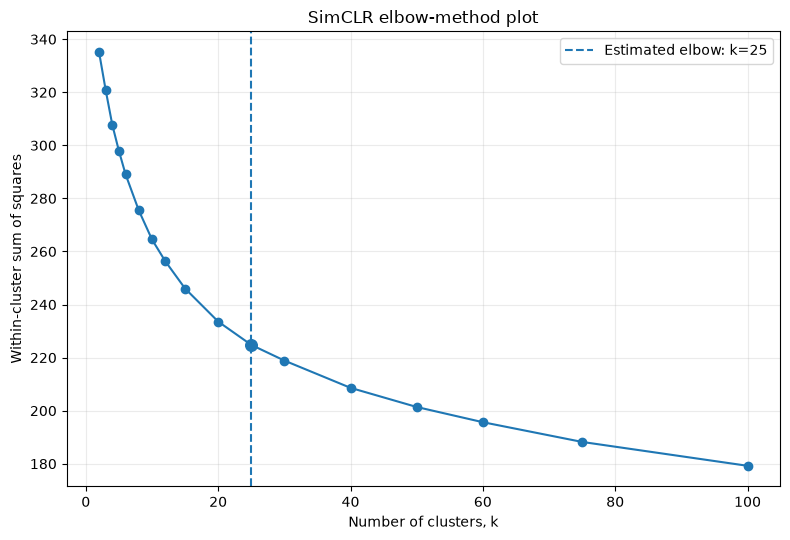

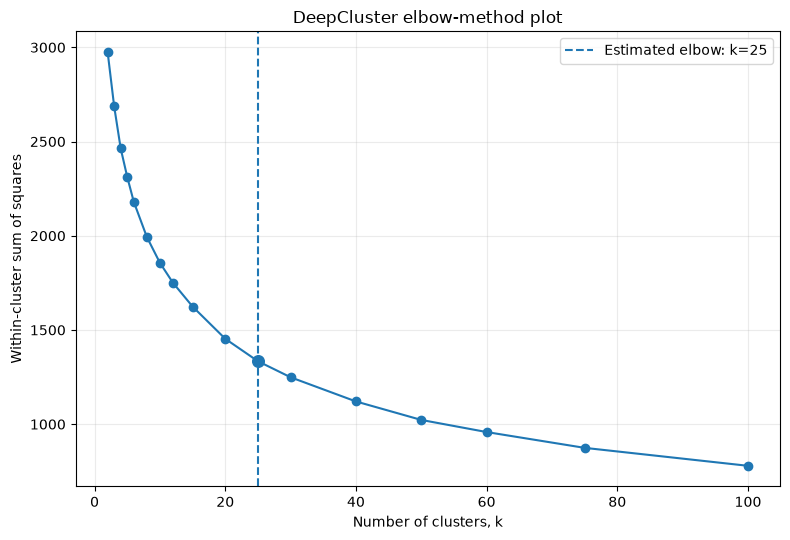

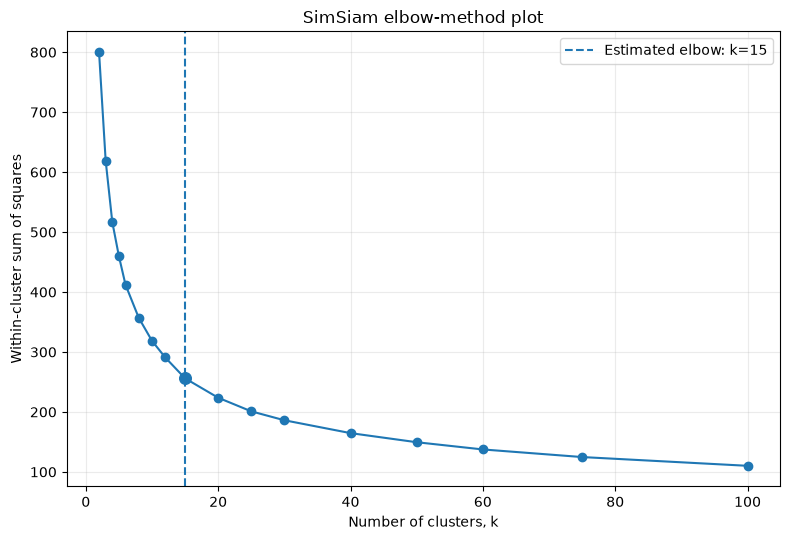

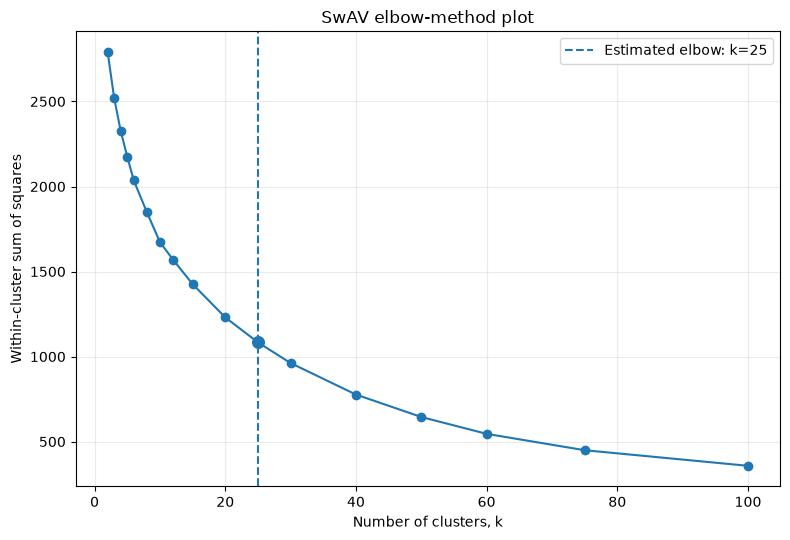


ELBOW-METHOD ANALYSIS: PASS
Validation sample rows: 5000
Candidate k values: [2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 40, 50, 60, 75, 100]
TEST SPLIT ACCESSED: NO


In [6]:
from sklearn.cluster import KMeans


ELBOW_K_VALUES = np.array(
    [
        2,
        3,
        4,
        5,
        6,
        8,
        10,
        12,
        15,
        20,
        25,
        30,
        40,
        50,
        60,
        75,
        100,
    ],
    dtype=int,
)

ELBOW_SAMPLE_INDICES = (
    silhouette_indices.copy()
)

ELBOW_SEED = 42
ELBOW_N_INIT = 5


def estimate_elbow(
    k_values: np.ndarray,
    inertia_values: np.ndarray,
) -> tuple[int, np.ndarray]:
    """Estimate the point furthest from the endpoint line."""

    x = np.asarray(
        k_values,
        dtype=np.float64,
    )

    y = np.asarray(
        inertia_values,
        dtype=np.float64,
    )

    x_range = float(
        x.max() - x.min()
    )

    y_range = float(
        y.max() - y.min()
    )

    if x_range <= 0 or y_range <= 0:
        return int(x[0]), np.zeros_like(x)

    x_scaled = (
        x - x.min()
    ) / x_range

    y_scaled = (
        y - y.min()
    ) / y_range

    start = np.array(
        [
            x_scaled[0],
            y_scaled[0],
        ],
        dtype=np.float64,
    )

    end = np.array(
        [
            x_scaled[-1],
            y_scaled[-1],
        ],
        dtype=np.float64,
    )

    line_vector = end - start
    line_length = float(
        np.linalg.norm(line_vector)
    )

    if line_length == 0:
        return int(x[0]), np.zeros_like(x)

    points = np.column_stack(
        [
            x_scaled,
            y_scaled,
        ]
    )

    relative_points = points - start

    distances = np.abs(
        (
            line_vector[0]
            * relative_points[:, 1]
        )
        - (
            line_vector[1]
            * relative_points[:, 0]
        )
    ) / line_length

    elbow_index = int(
        np.argmax(distances)
    )

    return (
        int(k_values[elbow_index]),
        distances,
    )


elbow_rows = []
elbow_summary_rows = []
elbow_results = {}

for display_name in MODEL_SPECS:
    print()
    print(
        f"Elbow analysis: {display_name}"
    )

    sample_coordinates = (
        common_results[
            display_name
        ]["coordinates"][
            ELBOW_SAMPLE_INDICES
        ]
    )

    inertia_values = []

    for number_of_clusters in (
        ELBOW_K_VALUES
    ):
        model = KMeans(
            n_clusters=int(
                number_of_clusters
            ),
            random_state=ELBOW_SEED,
            n_init=ELBOW_N_INIT,
            max_iter=300,
            tol=1e-4,
            algorithm="lloyd",
        )

        model.fit(
            sample_coordinates
        )

        inertia = float(
            model.inertia_
        )

        inertia_values.append(
            inertia
        )

        elbow_rows.append(
            {
                "Model": display_name,
                "k": int(
                    number_of_clusters
                ),
                "Inertia": inertia,
                "Sample crystals": int(
                    len(
                        ELBOW_SAMPLE_INDICES
                    )
                ),
                "PCA components": int(
                    sample_coordinates.shape[1]
                ),
                "Random seed": (
                    ELBOW_SEED
                ),
                "K-means initialisations": (
                    ELBOW_N_INIT
                ),
            }
        )

        print(
            f"  k={number_of_clusters:3d} "
            f"inertia={inertia:.3f}"
        )

    inertia_values = np.asarray(
        inertia_values,
        dtype=np.float64,
    )

    elbow_k, elbow_distances = (
        estimate_elbow(
            ELBOW_K_VALUES,
            inertia_values,
        )
    )

    elbow_results[display_name] = {
        "k_values": (
            ELBOW_K_VALUES.copy()
        ),
        "inertia": inertia_values,
        "elbow_distances": (
            elbow_distances
        ),
        "estimated_elbow_k": (
            elbow_k
        ),
    }

    elbow_summary_rows.append(
        {
            "Model": display_name,
            "Estimated elbow k": (
                elbow_k
            ),
            "Minimum tested k": int(
                ELBOW_K_VALUES.min()
            ),
            "Maximum tested k": int(
                ELBOW_K_VALUES.max()
            ),
            "Sample crystals": int(
                len(
                    ELBOW_SAMPLE_INDICES
                )
            ),
            "PCA components": int(
                sample_coordinates.shape[1]
            ),
        }
    )

elbow_table = pd.DataFrame(
    elbow_rows
)

elbow_summary = pd.DataFrame(
    elbow_summary_rows
)

elbow_table.to_csv(
    TABLE_ROOT
    / "elbow_method_inertia.csv",
    index=False,
)

elbow_summary.to_csv(
    TABLE_ROOT
    / "elbow_method_summary.csv",
    index=False,
)

display(elbow_summary)

figure, axes = plt.subplots(
    2,
    2,
    figsize=(14, 11),
)

for axis, display_name in zip(
    axes.ravel(),
    MODEL_SPECS,
):
    result = elbow_results[
        display_name
    ]

    axis.plot(
        result["k_values"],
        result["inertia"],
        marker="o",
    )

    elbow_k = int(
        result["estimated_elbow_k"]
    )

    elbow_index = int(
        np.flatnonzero(
            result["k_values"]
            == elbow_k
        )[0]
    )

    elbow_inertia = float(
        result["inertia"][
            elbow_index
        ]
    )

    axis.axvline(
        elbow_k,
        linestyle="--",
        linewidth=1.5,
        label=(
            f"Estimated elbow: "
            f"k={elbow_k}"
        ),
    )

    axis.scatter(
        [elbow_k],
        [elbow_inertia],
        s=65,
        zorder=5,
    )

    axis.set_title(
        display_name
    )

    axis.set_xlabel(
        "Number of clusters, k"
    )

    axis.set_ylabel(
        "Within-cluster sum of squares"
    )

    axis.grid(
        alpha=0.25
    )

    axis.legend()

figure.suptitle(
    (
        "Elbow-method comparison using the same "
        "5,000 validation crystals"
    ),
    fontsize=15,
)

figure.tight_layout()

elbow_overview_path = (
    FIGURE_ROOT
    / "elbow_method_four_model_overview.png"
)

figure.savefig(
    elbow_overview_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)


for display_name in MODEL_SPECS:
    result = elbow_results[
        display_name
    ]

    figure, axis = plt.subplots(
        figsize=(8, 5.5)
    )

    axis.plot(
        result["k_values"],
        result["inertia"],
        marker="o",
    )

    elbow_k = int(
        result["estimated_elbow_k"]
    )

    elbow_index = int(
        np.flatnonzero(
            result["k_values"]
            == elbow_k
        )[0]
    )

    elbow_inertia = float(
        result["inertia"][
            elbow_index
        ]
    )

    axis.axvline(
        elbow_k,
        linestyle="--",
        linewidth=1.5,
        label=(
            f"Estimated elbow: "
            f"k={elbow_k}"
        ),
    )

    axis.scatter(
        [elbow_k],
        [elbow_inertia],
        s=70,
        zorder=5,
    )

    axis.set_title(
        f"{display_name} elbow-method plot"
    )

    axis.set_xlabel(
        "Number of clusters, k"
    )

    axis.set_ylabel(
        "Within-cluster sum of squares"
    )

    axis.grid(
        alpha=0.25
    )

    axis.legend()

    figure.tight_layout()

    method = MODEL_SPECS[
        display_name
    ]["method"]

    individual_path = (
        FIGURE_ROOT
        / (
            f"{method}_elbow_method.png"
        )
    )

    figure.savefig(
        individual_path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(figure)

print()
print(
    "ELBOW-METHOD ANALYSIS: PASS"
)

print(
    "Validation sample rows:",
    len(ELBOW_SAMPLE_INDICES),
)

print(
    "Candidate k values:",
    ELBOW_K_VALUES.tolist(),
)

print("TEST SPLIT ACCESSED: NO")

## 6. Agreement between model clusterings

Adjusted Rand index, or ARI, compares two complete sets of cluster assignments.

- **ARI = 1:** the two models created the same grouping, apart from cluster
  number names.
- **ARI near 0:** their agreement is similar to chance.
- **Negative ARI:** they disagree more than would normally be expected by
  chance.

A low ARI does not automatically mean one model is wrong. Different
representations may emphasise different properties of the crystals.


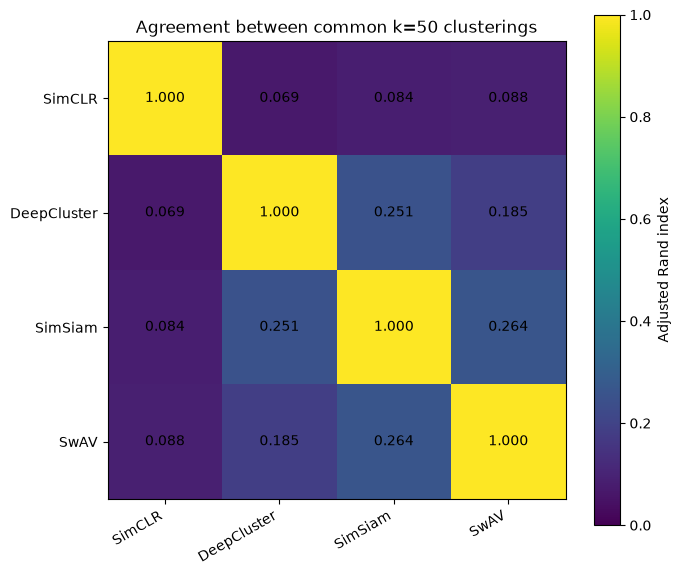

,Model A,Model B,Adjusted Rand index
0,SimCLR,DeepCluster,0.0693
1,SimCLR,SimSiam,0.0843
2,SimCLR,SwAV,0.0885
3,DeepCluster,SimSiam,0.2513
4,DeepCluster,SwAV,0.1851
5,SimSiam,SwAV,0.2635


In [7]:
model_names = list(
    MODEL_SPECS
)

ari_matrix = np.eye(
    len(model_names),
    dtype=float,
)

ari_rows = []

for left_index, right_index in combinations(
    range(len(model_names)),
    2,
):
    left_name = model_names[left_index]
    right_name = model_names[right_index]

    ari = float(
        adjusted_rand_score(
            common_results[
                left_name
            ]["labels"],
            common_results[
                right_name
            ]["labels"],
        )
    )

    ari_matrix[
        left_index,
        right_index,
    ] = ari

    ari_matrix[
        right_index,
        left_index,
    ] = ari

    ari_rows.append(
        {
            "Model A": left_name,
            "Model B": right_name,
            "Adjusted Rand index": ari,
        }
    )

ari_table = pd.DataFrame(
    ari_rows
)

ari_table.to_csv(
    TABLE_ROOT
    / "common_k50_pairwise_ari.csv",
    index=False,
)

figure, axis = plt.subplots(
    figsize=(7, 6)
)

image = axis.imshow(
    ari_matrix,
    vmin=0,
    vmax=1,
)

axis.set_xticks(
    np.arange(len(model_names)),
    labels=model_names,
    rotation=30,
    ha="right",
)

axis.set_yticks(
    np.arange(len(model_names)),
    labels=model_names,
)

for row_index in range(
    len(model_names)
):
    for column_index in range(
        len(model_names)
    ):
        axis.text(
            column_index,
            row_index,
            f"{ari_matrix[row_index, column_index]:.3f}",
            ha="center",
            va="center",
        )

axis.set_title(
    "Agreement between common k=50 clusterings"
)

figure.colorbar(
    image,
    ax=axis,
    label="Adjusted Rand index",
)

figure.tight_layout()

ari_figure_path = (
    FIGURE_ROOT
    / "common_k50_pairwise_ari.png"
)

figure.savefig(
    ari_figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)

display(
    ari_table.style.format(
        {
            "Adjusted Rand index": "{:.4f}"
        }
    )
)


## 7. Representative images from model clusters

The next panels show image examples from the twelve largest clusters produced
by each model at \(k=50\).

For each displayed cluster, the six crystals closest to its k-means centroid
are selected. These are central examples of the cluster rather than unusual
edge cases.

Only twelve clusters are displayed because showing all fifty clusters for all
four models would make the notebook difficult to inspect. Assignment tables
for every validation crystal are still saved in the comparison output folder.

When interpreting the panels, look for repeated visual properties such as:

- zoning patterns;
- brightness and contrast;
- crystal shape;
- fractures or inclusions;
- black-background proportion;
- crop size and orientation.

Consistent texture patterns may indicate meaningful representation learning.
Repeated acquisition artefacts or background patterns may indicate
confounding.


Selected validation image column: image_relative_path
Candidate path scores: {'image_relative_path': 250, 'source_image_relative_path': 0}



SimCLR
/home/ars223/MSc-GEMS/IRP26/runs/analysis/comparison/four_model_validation_v1/cluster_images/simclr_largest_cluster_examples.png


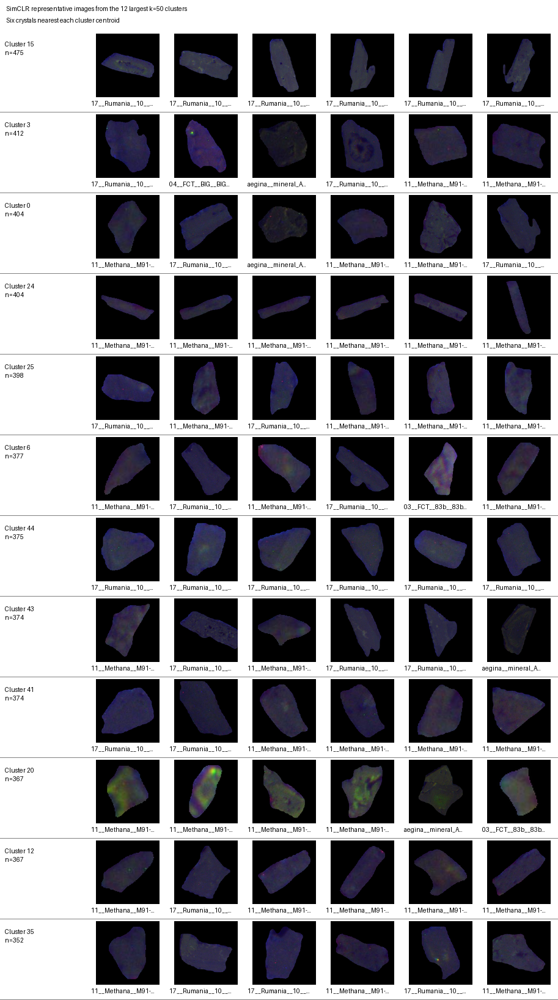


DeepCluster
/home/ars223/MSc-GEMS/IRP26/runs/analysis/comparison/four_model_validation_v1/cluster_images/deepcluster_largest_cluster_examples.png


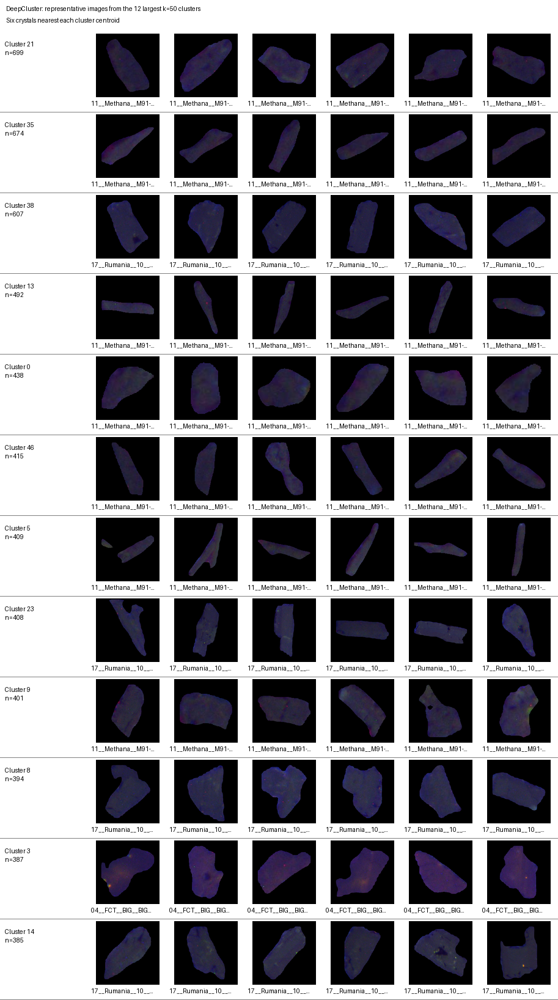


SimSiam
/home/ars223/MSc-GEMS/IRP26/runs/analysis/comparison/four_model_validation_v1/cluster_images/simsiam_largest_cluster_examples.png


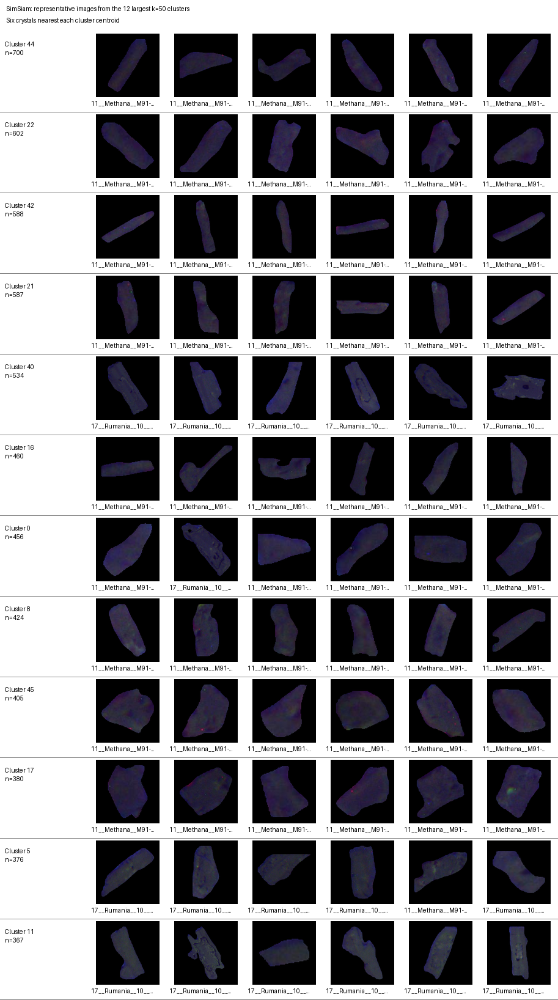


SwAV
/home/ars223/MSc-GEMS/IRP26/runs/analysis/comparison/four_model_validation_v1/cluster_images/swav_largest_cluster_examples.png


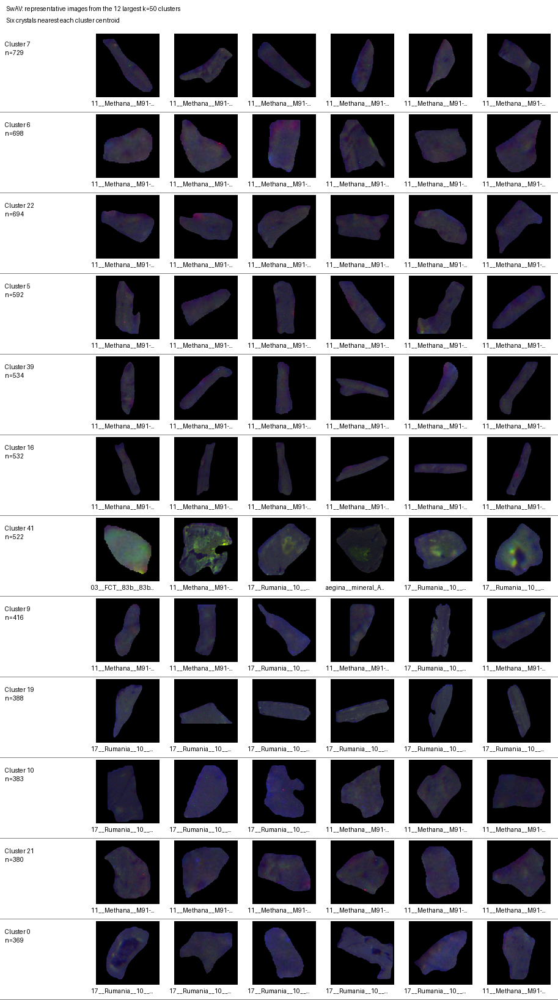


Validation images displayed: 288
TEST IMAGES ACCESSED: NO


In [8]:
IMAGE_COLUMN_CANDIDATES = (
    "image_relative_path",
    "masked_relative_path",
    "crystal_relative_path",
    "segmented_relative_path",
    "source_image_relative_path",
    "image_path",
    "relative_path",
    "filepath",
    "file_path",
    "path",
    "image",
    "filename",
)

LOCALITY_COLUMN = first_column(
    validation_manifest_raw,
    (
        "locality",
        "volcano",
        "site",
        "location",
    ),
)

SAMPLE_COLUMN = first_column(
    validation_manifest_raw,
    (
        "physical_sample_id",
        "sample_id",
        "sample",
        "sample_name",
        "specimen_id",
    ),
)

candidate_roots = [
    (
        IRP_ROOT
        / "data"
        / "processed"
        / "plagnetplus"
        / "ssl_non_aegina_v1"
    ),
    (
        IRP_ROOT
        / "data"
        / "processed"
        / "plagnetplus"
        / "ssl_aegina_compat_v1"
    ),
    (
        IRP_ROOT
        / "data"
        / "processed"
        / "plagnetplus"
        / "ssl_fct_6861_original_v1"
    ),
    UNIFIED_ROOT,
    BENCHMARK_ROOT,
    BENCHMARK_ROOT.parent,
    UNIFIED_ROOT / "images",
    UNIFIED_ROOT / "images_masked",
    IRP_ROOT,
    IRP_ROOT / "data",
    IRP_ROOT / "data" / "processed",
]

def resolve_image_path(
    raw_value: Any,
) -> Path:
    value = str(raw_value).strip()

    if not value:
        return Path(
            "/path/does/not/exist"
        )

    raw_path = Path(value)

    if raw_path.is_absolute():
        return raw_path

    for root in candidate_roots:
        candidate = root / raw_path

        if candidate.is_file():
            return candidate

    return UNIFIED_ROOT / raw_path

def choose_image_column(
    frame: pd.DataFrame,
) -> tuple[str, dict[str, int]]:
    available = [
        column
        for column in IMAGE_COLUMN_CANDIDATES
        if column in frame.columns
    ]

    available.extend(
        column
        for column in frame.columns
        if (
            column not in available
            and (
                "path" in column.lower()
                or "filename" in column.lower()
            )
        )
    )

    if not available:
        raise RuntimeError(
            "No possible image-path column was found."
        )

    sample_indices = np.linspace(
        0,
        len(frame) - 1,
        num=min(250, len(frame)),
        dtype=int,
    )

    scores = {}

    for column in available:
        resolved = 0

        for row_index in sample_indices:
            path = resolve_image_path(
                frame.iloc[
                    row_index
                ][column]
            )

            if path.is_file():
                resolved += 1

        scores[column] = resolved

    best_column = max(
        scores,
        key=scores.get,
    )

    if scores[best_column] == 0:
        raise RuntimeError(
            "Image paths could not be resolved. "
            f"Candidate scores: {scores}"
        )

    return best_column, scores

reference_manifest = (
    aligned_manifests["SimCLR"]
    .reset_index(drop=True)
)

image_column, image_column_scores = (
    choose_image_column(
        reference_manifest
    )
)

print(
    "Selected validation image column:",
    image_column,
)

print(
    "Candidate path scores:",
    image_column_scores,
)

try:
    RESAMPLE = Image.Resampling.LANCZOS
except AttributeError:
    RESAMPLE = Image.LANCZOS

FONT = ImageFont.load_default()

THUMBNAIL_SIZE = 104
IMAGES_PER_CLUSTER = 6
DISPLAY_CLUSTER_COUNT = 12
LABEL_WIDTH = 145
CELL_WIDTH = 128
ROW_HEIGHT = 132
HEADER_HEIGHT = 52

def shorten(
    value: Any,
    maximum: int,
) -> str:
    text = str(value)

    if len(text) <= maximum:
        return text

    return text[: maximum - 1] + "…"

def make_cluster_sheet(
    display_name: str,
) -> tuple[Path, pd.DataFrame]:
    result = common_results[
        display_name
    ]

    labels = result["labels"]
    coordinates = result[
        "coordinates"
    ]
    centroids = result["centroids"]
    counts = result["counts"]

    largest_clusters = np.argsort(
        counts
    )[::-1][
        :DISPLAY_CLUSTER_COUNT
    ]

    sheet_width = (
        LABEL_WIDTH
        + IMAGES_PER_CLUSTER
        * CELL_WIDTH
    )

    sheet_height = (
        HEADER_HEIGHT
        + DISPLAY_CLUSTER_COUNT
        * ROW_HEIGHT
    )

    sheet = Image.new(
        "RGB",
        (
            sheet_width,
            sheet_height,
        ),
        "white",
    )

    draw = ImageDraw.Draw(sheet)

    draw.text(
        (10, 8),
        (
            f"{display_name}: representative "
            "images from the 12 largest k=50 clusters"
        ),
        fill="black",
        font=FONT,
    )

    draw.text(
        (10, 27),
        (
            "Six crystals nearest each "
            "cluster centroid"
        ),
        fill="black",
        font=FONT,
    )

    selection_rows = []

    for display_row, cluster_id in enumerate(
        largest_clusters
    ):
        member_indices = np.flatnonzero(
            labels == cluster_id
        )

        distances = np.linalg.norm(
            coordinates[member_indices]
            - centroids[cluster_id],
            axis=1,
        )

        selected_indices = member_indices[
            np.argsort(distances)[
                :IMAGES_PER_CLUSTER
            ]
        ]

        y0 = (
            HEADER_HEIGHT
            + display_row
            * ROW_HEIGHT
        )

        draw.text(
            (8, y0 + 14),
            (
                f"Cluster {cluster_id}\n"
                f"n={counts[cluster_id]}"
            ),
            fill="black",
            font=FONT,
        )

        for image_rank, row_index in enumerate(
            selected_indices,
            start=1,
        ):
            manifest_row = (
                reference_manifest.iloc[
                    row_index
                ]
            )

            image_path = resolve_image_path(
                manifest_row[
                    image_column
                ]
            )

            try:
                with Image.open(
                    image_path
                ) as source:
                    source_image = (
                        source.convert("RGB")
                    )

                    thumbnail = (
                        ImageOps.contain(
                            source_image,
                            (
                                THUMBNAIL_SIZE,
                                THUMBNAIL_SIZE,
                            ),
                            method=RESAMPLE,
                        )
                    )

            except Exception as error:
                thumbnail = Image.new(
                    "RGB",
                    (
                        THUMBNAIL_SIZE,
                        THUMBNAIL_SIZE,
                    ),
                    "white",
                )

                error_draw = ImageDraw.Draw(
                    thumbnail
                )

                error_draw.text(
                    (4, 4),
                    (
                        "IMAGE\n"
                        "UNAVAILABLE"
                    ),
                    fill="black",
                    font=FONT,
                )

            x0 = (
                LABEL_WIDTH
                + (image_rank - 1)
                * CELL_WIDTH
            )

            paste_x = (
                x0
                + (
                    CELL_WIDTH
                    - thumbnail.width
                )
                // 2
            )

            paste_y = y0 + 3

            sheet.paste(
                thumbnail,
                (
                    paste_x,
                    paste_y,
                ),
            )

            crystal_id = str(
                manifest_row[
                    "crystal_id"
                ]
            )

            draw.text(
                (
                    x0 + 4,
                    y0 + THUMBNAIL_SIZE + 7,
                ),
                shorten(
                    crystal_id,
                    18,
                ),
                fill="black",
                font=FONT,
            )

            selection_rows.append(
                {
                    "Model": display_name,
                    "Cluster": int(
                        cluster_id
                    ),
                    "Cluster size": int(
                        counts[cluster_id]
                    ),
                    "Image rank": image_rank,
                    "crystal_id": crystal_id,
                    "manifest_order": int(
                        manifest_row[
                            "manifest_order"
                        ]
                    ),
                    "distance_to_centroid": float(
                        np.linalg.norm(
                            coordinates[
                                row_index
                            ]
                            - centroids[
                                cluster_id
                            ]
                        )
                    ),
                    "image_path": str(
                        image_path
                    ),
                    "locality": (
                        str(
                            manifest_row[
                                LOCALITY_COLUMN
                            ]
                        )
                        if LOCALITY_COLUMN
                        else None
                    ),
                    "sample": (
                        str(
                            manifest_row[
                                SAMPLE_COLUMN
                            ]
                        )
                        if SAMPLE_COLUMN
                        else None
                    ),
                }
            )

        draw.line(
            (
                0,
                y0 + ROW_HEIGHT - 1,
                sheet_width,
                y0 + ROW_HEIGHT - 1,
            ),
            fill="grey",
            width=1,
        )

    output_path = (
        IMAGE_CLUSTER_ROOT
        / (
            f"{MODEL_SPECS[display_name]['method']}"
            "_largest_cluster_examples.png"
        )
    )

    sheet.save(
        output_path,
        format="PNG",
        optimize=True,
    )

    selection_table = pd.DataFrame(
        selection_rows
    )

    selection_table.to_csv(
        IMAGE_CLUSTER_ROOT
        / (
            f"{MODEL_SPECS[display_name]['method']}"
            "_cluster_image_selection.csv"
        ),
        index=False,
    )

    return output_path, selection_table

cluster_image_outputs = {}
cluster_selection_tables = []

for display_name in MODEL_SPECS:
    output_path, selection_table = (
        make_cluster_sheet(
            display_name
        )
    )

    cluster_image_outputs[
        display_name
    ] = str(output_path)

    cluster_selection_tables.append(
        selection_table
    )

    print()
    print(display_name)
    print(output_path)

    display(
        NotebookImage(
            filename=str(output_path)
        )
    )

all_cluster_selections = pd.concat(
    cluster_selection_tables,
    ignore_index=True,
)

all_cluster_selections.to_csv(
    TABLE_ROOT
    / "all_cluster_image_selections.csv",
    index=False,
)

print()
print(
    "Validation images displayed:",
    len(all_cluster_selections),
)

print("TEST IMAGES ACCESSED: NO")


## 8. Model-specific elbow clustering and image samples

The common \(k=50\) analysis is useful because it compares every model under
exactly the same clustering conditions. However, the elbow analysis suggests
that a smaller number of clusters may describe the main structure learned by
each model more clearly.

This section therefore reclusters each model using its own estimated elbow
value. It shows:

- the elbow curve and selected \(k\);
- the corresponding PCA cluster layout;
- cluster-size balance;
- six representative crystal images from every selected cluster.

The representative images are the crystals nearest to each k-means cluster
centre. They are intended to show the typical visual properties of a cluster,
rather than unusual examples near its boundary.

The elbow-selected clusters remain exploratory. A cluster is not automatically
a distinct geological crystal population. Meaningful interpretation requires
checking whether its images share crystal textures rather than locality,
background, crop size or acquisition characteristics.


Elbow-selected clustering: SimCLR, k=25



Elbow-selected clustering: DeepCluster, k=25



Elbow-selected clustering: SimSiam, k=15



Elbow-selected clustering: SwAV, k=25


,Model,Selected elbow k,Elbow-k silhouette,Common k=50 silhouette,Silhouette change from k=50,Davies-Bouldin,Calinski-Harabasz,Occupied clusters,Normalised size entropy,Smallest cluster,Largest cluster,Largest cluster fraction
0,SimCLR,25,0.0608,0.0541,+0.0067,2.5335,119.9,25,0.9942,287,840,0.0563
1,DeepCluster,25,0.1777,0.1671,+0.0106,1.6831,334.3,25,0.9814,253,1129,0.0757
2,SimSiam,15,0.2152,0.1599,+0.0553,1.2710,1078.0,15,0.9714,367,1926,0.1291
3,SwAV,25,0.2918,0.3117,-0.0199,1.5254,394.5,25,0.9467,184,1998,0.1339


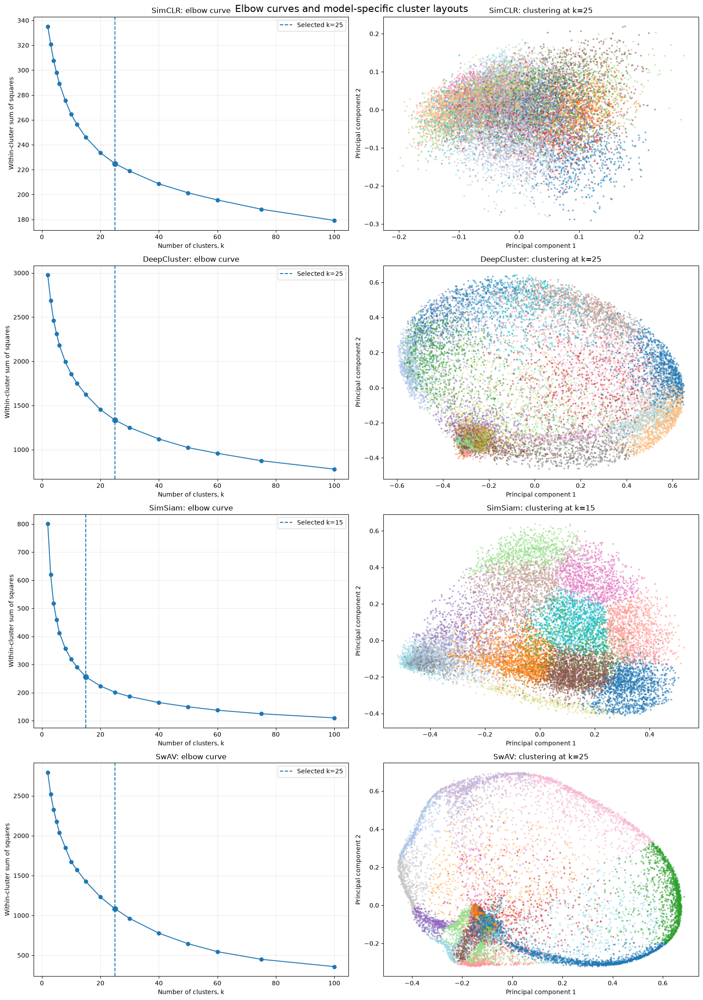

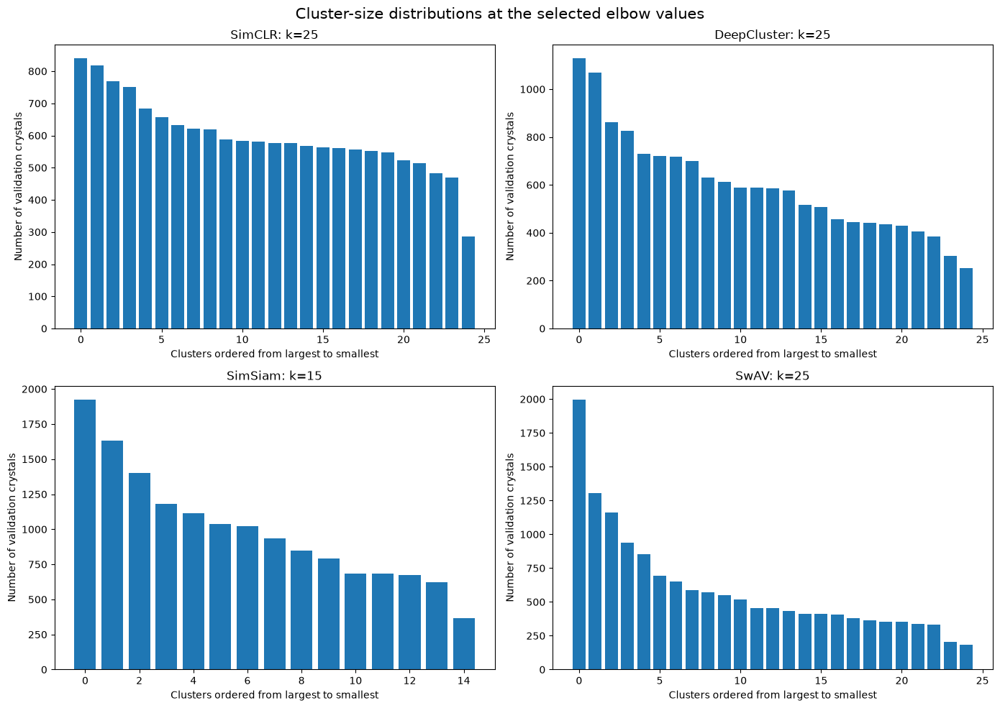


SimCLR elbow-selected cluster images
/home/ars223/MSc-GEMS/IRP26/runs/analysis/comparison/four_model_validation_v1/cluster_images/simclr_elbow_k25_all_clusters.png


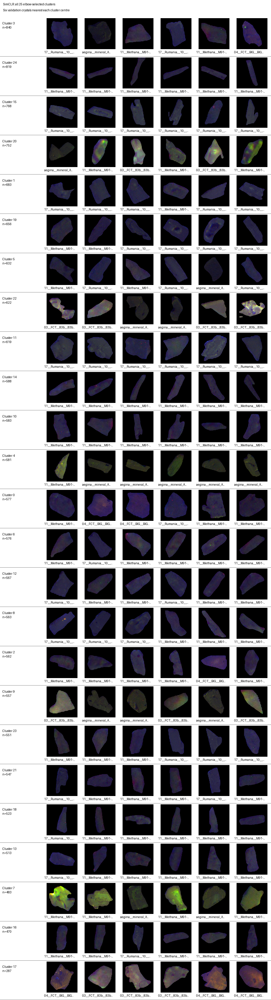


DeepCluster elbow-selected cluster images
/home/ars223/MSc-GEMS/IRP26/runs/analysis/comparison/four_model_validation_v1/cluster_images/deepcluster_elbow_k25_all_clusters.png


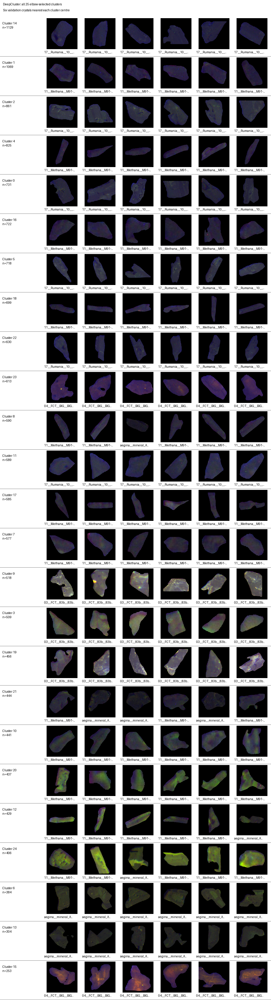


SimSiam elbow-selected cluster images
/home/ars223/MSc-GEMS/IRP26/runs/analysis/comparison/four_model_validation_v1/cluster_images/simsiam_elbow_k15_all_clusters.png


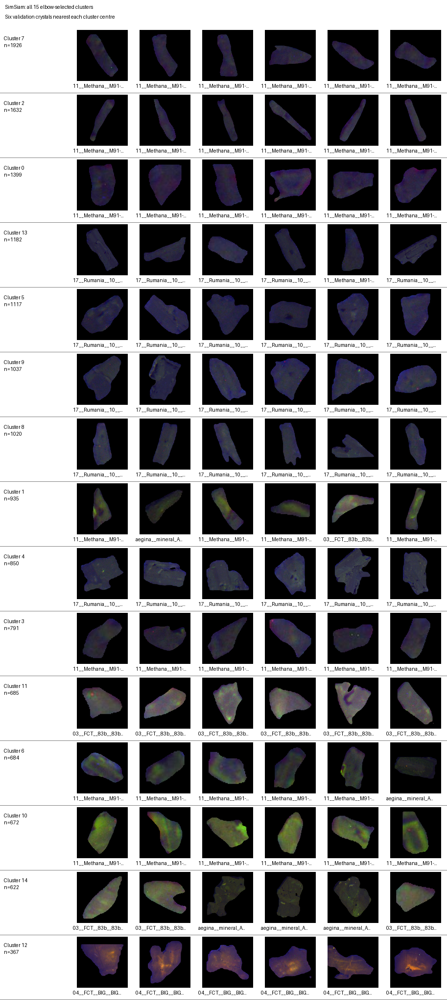


SwAV elbow-selected cluster images
/home/ars223/MSc-GEMS/IRP26/runs/analysis/comparison/four_model_validation_v1/cluster_images/swav_elbow_k25_all_clusters.png


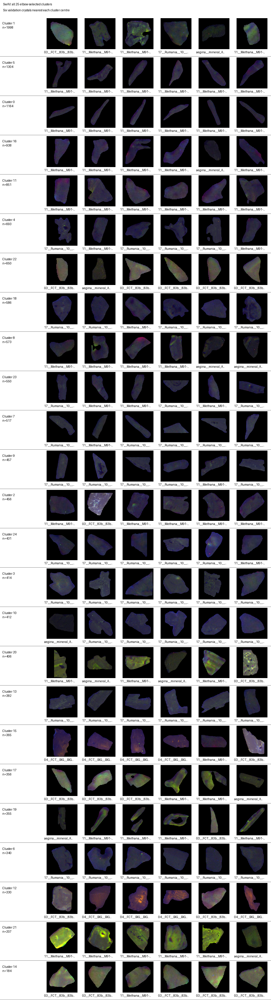


ELBOW-SELECTED CLUSTER PANELS: PASS
Representative images displayed: 540
TEST IMAGES ACCESSED: NO


In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)


ELBOW_CLUSTER_SEED = 42
ELBOW_CLUSTER_N_INIT = 10
ELBOW_IMAGES_PER_CLUSTER = 6
ELBOW_HEADER_HEIGHT = 58


elbow_selected_results = {}
elbow_selected_metric_rows = []


common_metric_lookup = (
    common_metrics
    .set_index("Model")
)


for display_name in MODEL_SPECS:
    selected_k = int(
        elbow_results[
            display_name
        ]["estimated_elbow_k"]
    )

    coordinates = (
        common_results[
            display_name
        ]["coordinates"]
    )

    print()
    print(
        f"Elbow-selected clustering: "
        f"{display_name}, k={selected_k}"
    )

    model = KMeans(
        n_clusters=selected_k,
        random_state=(
            ELBOW_CLUSTER_SEED
        ),
        n_init=ELBOW_CLUSTER_N_INIT,
        max_iter=300,
        tol=1e-4,
        algorithm="lloyd",
    )

    labels = model.fit_predict(
        coordinates
    )

    centroids = (
        model.cluster_centers_
    )

    counts = np.bincount(
        labels,
        minlength=selected_k,
    )

    proportions = (
        counts
        / counts.sum()
    )

    occupied_proportions = (
        proportions[
            proportions > 0
        ]
    )

    normalised_entropy = float(
        -np.sum(
            occupied_proportions
            * np.log(
                occupied_proportions
            )
        )
        / np.log(selected_k)
    )

    sample_coordinates = (
        coordinates[
            silhouette_indices
        ]
    )

    sample_labels = (
        labels[
            silhouette_indices
        ]
    )

    silhouette = float(
        silhouette_score(
            sample_coordinates,
            sample_labels,
            metric="euclidean",
        )
    )

    davies_bouldin = float(
        davies_bouldin_score(
            sample_coordinates,
            sample_labels,
        )
    )

    calinski_harabasz = float(
        calinski_harabasz_score(
            sample_coordinates,
            sample_labels,
        )
    )

    common_k50_silhouette = float(
        common_metric_lookup.loc[
            display_name,
            "Silhouette",
        ]
    )

    elbow_selected_results[
        display_name
    ] = {
        "selected_k": selected_k,
        "coordinates": coordinates,
        "labels": labels,
        "centroids": centroids,
        "counts": counts,
        "inertia": float(
            model.inertia_
        ),
        "silhouette": silhouette,
        "davies_bouldin": (
            davies_bouldin
        ),
        "calinski_harabasz": (
            calinski_harabasz
        ),
    }

    elbow_selected_metric_rows.append(
        {
            "Model": display_name,
            "Selected elbow k": (
                selected_k
            ),
            "Elbow-k silhouette": (
                silhouette
            ),
            "Common k=50 silhouette": (
                common_k50_silhouette
            ),
            "Silhouette change from k=50": (
                silhouette
                - common_k50_silhouette
            ),
            "Davies-Bouldin": (
                davies_bouldin
            ),
            "Calinski-Harabasz": (
                calinski_harabasz
            ),
            "Occupied clusters": int(
                np.count_nonzero(
                    counts
                )
            ),
            "Normalised size entropy": (
                normalised_entropy
            ),
            "Smallest cluster": int(
                counts.min()
            ),
            "Largest cluster": int(
                counts.max()
            ),
            "Largest cluster fraction": float(
                counts.max()
                / counts.sum()
            ),
        }
    )

    assignment_table = pd.DataFrame(
        {
            "crystal_id": (
                common_results[
                    display_name
                ]["crystal_ids"]
            ),
            "manifest_order": (
                common_results[
                    display_name
                ]["manifest_orders"]
            ),
            "cluster": labels,
        }
    )

    method = MODEL_SPECS[
        display_name
    ]["method"]

    assignment_table.to_csv(
        CLUSTER_ROOT
        / (
            f"{method}_elbow_k"
            f"{selected_k}_assignments.csv"
        ),
        index=False,
    )


elbow_selected_metrics = pd.DataFrame(
    elbow_selected_metric_rows
)

elbow_selected_metrics.to_csv(
    TABLE_ROOT
    / "elbow_selected_clustering_metrics.csv",
    index=False,
)

display(
    elbow_selected_metrics.style.format(
        {
            "Elbow-k silhouette": "{:.4f}",
            "Common k=50 silhouette": "{:.4f}",
            "Silhouette change from k=50": (
                "{:+.4f}"
            ),
            "Davies-Bouldin": "{:.4f}",
            "Calinski-Harabasz": "{:.1f}",
            "Normalised size entropy": "{:.4f}",
            "Largest cluster fraction": "{:.4f}",
        }
    )
)


figure, axes = plt.subplots(
    4,
    2,
    figsize=(16, 23),
)


for row_index, display_name in enumerate(
    MODEL_SPECS
):
    elbow_axis = axes[
        row_index,
        0,
    ]

    cluster_axis = axes[
        row_index,
        1,
    ]

    elbow_result = elbow_results[
        display_name
    ]

    selected_result = (
        elbow_selected_results[
            display_name
        ]
    )

    selected_k = int(
        selected_result[
            "selected_k"
        ]
    )

    elbow_axis.plot(
        elbow_result[
            "k_values"
        ],
        elbow_result[
            "inertia"
        ],
        marker="o",
    )

    elbow_axis.axvline(
        selected_k,
        linestyle="--",
        linewidth=1.5,
        label=(
            f"Selected k={selected_k}"
        ),
    )

    selected_index = int(
        np.flatnonzero(
            elbow_result[
                "k_values"
            ]
            == selected_k
        )[0]
    )

    elbow_axis.scatter(
        [selected_k],
        [
            elbow_result[
                "inertia"
            ][selected_index]
        ],
        s=70,
        zorder=5,
    )

    elbow_axis.set_title(
        f"{display_name}: elbow curve"
    )

    elbow_axis.set_xlabel(
        "Number of clusters, k"
    )

    elbow_axis.set_ylabel(
        "Within-cluster sum of squares"
    )

    elbow_axis.grid(
        alpha=0.25
    )

    elbow_axis.legend()

    scatter = cluster_axis.scatter(
        selected_result[
            "coordinates"
        ][:, 0],
        selected_result[
            "coordinates"
        ][:, 1],
        c=selected_result[
            "labels"
        ],
        s=4,
        alpha=0.45,
        cmap="tab20",
    )

    cluster_axis.set_title(
        (
            f"{display_name}: "
            f"clustering at k={selected_k}"
        )
    )

    cluster_axis.set_xlabel(
        "Principal component 1"
    )

    cluster_axis.set_ylabel(
        "Principal component 2"
    )


figure.suptitle(
    (
        "Elbow curves and model-specific "
        "cluster layouts"
    ),
    fontsize=16,
)

figure.tight_layout()

elbow_cluster_layout_path = (
    FIGURE_ROOT
    / (
        "elbow_selected_k_"
        "and_cluster_layouts.png"
    )
)

figure.savefig(
    elbow_cluster_layout_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)


figure, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10),
)


for axis, display_name in zip(
    axes.ravel(),
    MODEL_SPECS,
):
    result = elbow_selected_results[
        display_name
    ]

    counts = np.sort(
        result["counts"]
    )[::-1]

    axis.bar(
        np.arange(
            len(counts)
        ),
        counts,
    )

    axis.set_title(
        (
            f"{display_name}: "
            f"k={result['selected_k']}"
        )
    )

    axis.set_xlabel(
        (
            "Clusters ordered from "
            "largest to smallest"
        )
    )

    axis.set_ylabel(
        "Number of validation crystals"
    )


figure.suptitle(
    "Cluster-size distributions at the selected elbow values",
    fontsize=15,
)

figure.tight_layout()

elbow_cluster_size_path = (
    FIGURE_ROOT
    / "elbow_selected_cluster_sizes.png"
)

figure.savefig(
    elbow_cluster_size_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)


def make_elbow_cluster_sheet(
    display_name: str,
) -> tuple[Path, pd.DataFrame]:
    result = elbow_selected_results[
        display_name
    ]

    selected_k = int(
        result["selected_k"]
    )

    labels = result["labels"]
    coordinates = result[
        "coordinates"
    ]
    centroids = result["centroids"]
    counts = result["counts"]

    cluster_ids = np.argsort(
        counts
    )[::-1]

    sheet_width = (
        LABEL_WIDTH
        + ELBOW_IMAGES_PER_CLUSTER
        * CELL_WIDTH
    )

    sheet_height = (
        ELBOW_HEADER_HEIGHT
        + len(cluster_ids)
        * ROW_HEIGHT
    )

    sheet = Image.new(
        "RGB",
        (
            sheet_width,
            sheet_height,
        ),
        "white",
    )

    draw = ImageDraw.Draw(
        sheet
    )

    draw.text(
        (10, 8),
        (
            f"{display_name}: all "
            f"{selected_k} elbow-selected clusters"
        ),
        fill="black",
        font=FONT,
    )

    draw.text(
        (10, 28),
        (
            "Six validation crystals nearest "
            "each cluster centre"
        ),
        fill="black",
        font=FONT,
    )

    selection_rows = []

    for display_row, cluster_id in enumerate(
        cluster_ids
    ):
        member_indices = np.flatnonzero(
            labels == cluster_id
        )

        distances = np.linalg.norm(
            coordinates[
                member_indices
            ]
            - centroids[
                cluster_id
            ],
            axis=1,
        )

        selected_indices = (
            member_indices[
                np.argsort(
                    distances
                )[
                    :ELBOW_IMAGES_PER_CLUSTER
                ]
            ]
        )

        y0 = (
            ELBOW_HEADER_HEIGHT
            + display_row
            * ROW_HEIGHT
        )

        draw.text(
            (8, y0 + 14),
            (
                f"Cluster {cluster_id}\n"
                f"n={counts[cluster_id]}"
            ),
            fill="black",
            font=FONT,
        )

        for image_rank, row_index in enumerate(
            selected_indices,
            start=1,
        ):
            manifest_row = (
                reference_manifest.iloc[
                    row_index
                ]
            )

            image_path = (
                resolve_image_path(
                    manifest_row[
                        image_column
                    ]
                )
            )

            try:
                with Image.open(
                    image_path
                ) as source:
                    source_image = (
                        source.convert(
                            "RGB"
                        )
                    )

                    thumbnail = (
                        ImageOps.contain(
                            source_image,
                            (
                                THUMBNAIL_SIZE,
                                THUMBNAIL_SIZE,
                            ),
                            method=RESAMPLE,
                        )
                    )

            except Exception:
                thumbnail = Image.new(
                    "RGB",
                    (
                        THUMBNAIL_SIZE,
                        THUMBNAIL_SIZE,
                    ),
                    "white",
                )

                error_draw = (
                    ImageDraw.Draw(
                        thumbnail
                    )
                )

                error_draw.text(
                    (4, 4),
                    "IMAGE\nUNAVAILABLE",
                    fill="black",
                    font=FONT,
                )

            x0 = (
                LABEL_WIDTH
                + (
                    image_rank - 1
                )
                * CELL_WIDTH
            )

            paste_x = (
                x0
                + (
                    CELL_WIDTH
                    - thumbnail.width
                )
                // 2
            )

            paste_y = y0 + 3

            sheet.paste(
                thumbnail,
                (
                    paste_x,
                    paste_y,
                ),
            )

            crystal_id = str(
                manifest_row[
                    "crystal_id"
                ]
            )

            draw.text(
                (
                    x0 + 4,
                    y0
                    + THUMBNAIL_SIZE
                    + 7,
                ),
                shorten(
                    crystal_id,
                    18,
                ),
                fill="black",
                font=FONT,
            )

            selection_rows.append(
                {
                    "Model": display_name,
                    "Selected elbow k": (
                        selected_k
                    ),
                    "Cluster": int(
                        cluster_id
                    ),
                    "Cluster size": int(
                        counts[
                            cluster_id
                        ]
                    ),
                    "Image rank": (
                        image_rank
                    ),
                    "crystal_id": (
                        crystal_id
                    ),
                    "manifest_order": int(
                        manifest_row[
                            "manifest_order"
                        ]
                    ),
                    "distance_to_centroid": float(
                        np.linalg.norm(
                            coordinates[
                                row_index
                            ]
                            - centroids[
                                cluster_id
                            ]
                        )
                    ),
                    "image_path": str(
                        image_path
                    ),
                    "locality": (
                        str(
                            manifest_row[
                                LOCALITY_COLUMN
                            ]
                        )
                        if LOCALITY_COLUMN
                        else None
                    ),
                    "sample": (
                        str(
                            manifest_row[
                                SAMPLE_COLUMN
                            ]
                        )
                        if SAMPLE_COLUMN
                        else None
                    ),
                }
            )

        draw.line(
            (
                0,
                y0 + ROW_HEIGHT - 1,
                sheet_width,
                y0 + ROW_HEIGHT - 1,
            ),
            fill="grey",
            width=1,
        )

    method = MODEL_SPECS[
        display_name
    ]["method"]

    output_path = (
        IMAGE_CLUSTER_ROOT
        / (
            f"{method}_elbow_k"
            f"{selected_k}_all_clusters.png"
        )
    )

    sheet.save(
        output_path,
        format="PNG",
        optimize=True,
    )

    selection_table = pd.DataFrame(
        selection_rows
    )

    selection_table.to_csv(
        IMAGE_CLUSTER_ROOT
        / (
            f"{method}_elbow_k"
            f"{selected_k}_image_selection.csv"
        ),
        index=False,
    )

    return (
        output_path,
        selection_table,
    )


elbow_cluster_image_outputs = {}
elbow_cluster_selection_tables = []


for display_name in MODEL_SPECS:
    output_path, selection_table = (
        make_elbow_cluster_sheet(
            display_name
        )
    )

    elbow_cluster_image_outputs[
        display_name
    ] = str(
        output_path
    )

    elbow_cluster_selection_tables.append(
        selection_table
    )

    print()
    print(
        f"{display_name} elbow-selected "
        "cluster images"
    )

    print(output_path)

    display(
        NotebookImage(
            filename=str(
                output_path
            )
        )
    )


all_elbow_cluster_selections = (
    pd.concat(
        elbow_cluster_selection_tables,
        ignore_index=True,
    )
)

all_elbow_cluster_selections.to_csv(
    TABLE_ROOT
    / (
        "elbow_selected_cluster_"
        "image_selections.csv"
    ),
    index=False,
)


print()
print(
    "ELBOW-SELECTED CLUSTER "
    "PANELS: PASS"
)

print(
    "Representative images displayed:",
    len(
        all_elbow_cluster_selections
    ),
)

print("TEST IMAGES ACCESSED: NO")

## 9. Overall interpretation

The four methods should be treated as complementary comparisons rather than
ranked using one opaque overall score.

- **SwAV** currently provides the strongest cluster separation, strongest
  cross-sample FCT retrieval and broadest effective representation.
- **DeepCluster** provides the most stable clusters and the lowest training
  cost, but its existing source-image enrichment is comparatively high.
- **SimSiam** provides the strongest locality probe result, but its very low
  effective rank indicates a narrow representation.
- **SimCLR** remains a useful balanced baseline with moderate stability,
  dimensionality and acquisition leakage.

The image panels are essential for deciding whether numerical cluster quality
corresponds to meaningful crystal textures or merely to acquisition and crop
characteristics.


In [10]:
def best_model(
    column: str,
    *,
    higher_is_better: bool,
) -> str | None:
    values = metrics_table[
        ["Model", column]
    ].dropna()

    if values.empty:
        return None

    index = (
        values[column].idxmax()
        if higher_is_better
        else values[column].idxmin()
    )

    return str(
        values.loc[index, "Model"]
    )

headline_results = {
    "best_reported_cluster_separation": (
        best_model(
            "Median silhouette",
            higher_is_better=True,
        )
    ),
    "best_reported_cluster_stability": (
        best_model(
            "Stability ARI",
            higher_is_better=True,
        )
    ),
    "best_fct_cross_sample_retrieval": (
        best_model(
            "FCT cross-sample P@10",
            higher_is_better=True,
        )
    ),
    "highest_locality_macro_f1": (
        best_model(
            "Locality macro-F1",
            higher_is_better=True,
        )
    ),
    "broadest_effective_representation": (
        best_model(
            "Effective rank",
            higher_is_better=True,
        )
    ),
    "lowest_gpu_cost": (
        best_model(
            "GPU hours",
            higher_is_better=False,
        )
    ),
}

comparison_summary = {
    "schema_version": (
        "plagnetplus_four_model_"
        "comparison_v1"
    ),
    "benchmark_id": (
        "pooled_broad_p80_10_10_v1"
    ),
    "evaluation_split": "validation",
    "models": list(MODEL_SPECS),
    "common_clustering": {
        "feature_dimension": 512,
        "normalisation": "row_l2",
        "pca_components": 50,
        "k": COMMON_K,
        "seed": COMMON_SEED,
        "silhouette_sample_rows": 5000,
    },
    "headline_results": (
        headline_results
    ),
    "cluster_image_outputs": (
        cluster_image_outputs
    ),
    "test_split_accessed": False,
}

write_json(
    OUTPUT_ROOT
    / "comparison_summary.json",
    comparison_summary,
)

headline_table = pd.DataFrame(
    [
        {
            "Comparison": key.replace(
                "_",
                " ",
            ).title(),
            "Model": value,
        }
        for key, value in (
            headline_results.items()
        )
    ]
)

headline_table.to_csv(
    TABLE_ROOT
    / "headline_results.csv",
    index=False,
)

display(headline_table)

print()
print(
    "FOUR-MODEL COMPARISON: PASS"
)
print(
    "Comparison summary:",
    OUTPUT_ROOT
    / "comparison_summary.json",
)
print(
    "Test split accessed: False"
)


,Comparison,Model
0,Best Reported Cluster Separation,SwAV
1,Best Reported Cluster Stability,DeepCluster
2,Best Fct Cross Sample Retrieval,SwAV
3,Highest Locality Macro F1,SimSiam
4,Broadest Effective Representation,SwAV
5,Lowest Gpu Cost,DeepCluster



FOUR-MODEL COMPARISON: PASS
Comparison summary: /home/ars223/MSc-GEMS/IRP26/runs/analysis/comparison/four_model_validation_v1/comparison_summary.json
Test split accessed: False
